In [87]:
### VARIABLES
# For current_gen, we use the game name instead as per VERSION_GROUPS
CURRENT_VERSION = "firered-leafgreen"
AVERAGE_STAT = 87
TARGET_BASE_POWER_FOR_ONESHOT = 340 # Assuming Level 50 Pokemon
SHOW_AS_HTML = True 

In [88]:
# ["HP", "ATK", "SP ATK", "DEF", "SP DEF", "SPD"]
# ["Base Power"]
# ["Setup"]
# ["Stat Change"]
# ["Status"]

# """
# Sweep: (SP)ATK+SPD
# Tank: HP+(SP)ATK, (SP)ATK+(SP)DEF, (SP)DEF++
# Wall: HP++, HP+(SP)DEF
# Wallbreaker: (SP)ATK++
# Utility: HP+SPD, DEF+SPD

# The stats alone are actually disingenuous. 
# HP+(SP)DEF leads to (SP) Bulk.
# ATK+BP leads to (SP) Power.
# SPD+SPD leads to SPD. 

# Translating: 
# Sweeper: (SP) Power + SPD
# Breaker: (SP) Power+
# Wall: (SP) Bulk+ 
# Tank: (SP) Bulk + (SP) Power
# Utility: (SP) Bulk + SPD, SPD+

# If we consider that there are 18 types, that means there is Sweeper-Normal, Sweeper-Fire, etc.
# Which means we have 5x18 = 90 roles.
# """

In [89]:
### IMPORTS
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
from tqdm import tqdm
from itertools import combinations, chain, product
from IPython.display import display, HTML
from warnings import simplefilter 
from time import perf_counter

### IMPORT CONFIGURATION
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', 500)

simplefilter(action="ignore", category=pd.errors.PerformanceWarning)

In [90]:
### LOAD DATAFRAMES
# VERSION GROUPS
# For linking CURRENT_GEN to game versions
VERSION_GROUPS = pd.read_csv("version_groups.csv")
# VERSION_GROUPS = VERSION_GROUPS.sort_values("order")
CURRENT_VERSION_GROUP = VERSION_GROUPS.loc[VERSION_GROUPS["identifier"] == CURRENT_VERSION, "id"].values[0]
CURRENT_GEN = VERSION_GROUPS.loc[VERSION_GROUPS["identifier"] == CURRENT_VERSION, "generation_id"].values[0]

# POKEMON.CSV
POKEMON = pd.read_csv("pokemon.csv", index_col="identifier")

# POKEMON_STATS.CSV
POKEMON_STATS = pd.read_csv("pokemon_stats.csv")

# STATS.CSV
STATS = pd.read_csv("stats.csv", index_col="id")

POKEMON_STATS_LABELS = ["hp", "atk", "def", "spatk", "spdef", "spd"]

# POKEMON_TYPES.CSV
POKEMON_TYPES = pd.read_csv("pokemon_types.csv")

# TYPES.CSV
# List of types
TYPES = pd.read_csv("types.csv", index_col="id")

# TYPE_CHART.CSV 
# Type effectiveness
TYPE_CHART = pd.read_csv("type_chart.csv", keep_default_na=False, index_col=0)

# Configure the type chart
if CURRENT_GEN <= 5: 
    # If we are not in Gen 6+, we reload the type chart to use the Gen2-5 chart
    # Gen 1 did not have Dark or Steel type, but this is largely irrelevant
    TYPE_CHART = pd.read_csv("type_chart_gen2-5.csv", keep_default_na=False, index_col=0)
if "Fairy" not in TYPE_CHART.index: 
    # In the case of Gen 5-, there is no Fairy type. 
    # However, POKEMON will still have Fairy typing, and this is usually set from Normal typing.
    # So, we give Fairy the same strengths and weaknesses as Normal.
    TYPE_CHART["Fai"] = TYPE_CHART["Nor"] 
    TYPE_CHART.loc["Fairy", :] = TYPE_CHART.loc["Normal", :]
    
TYPE_CHART.replace("½", "0.5", inplace=True)
TYPE_CHART.replace("", "1", inplace=True)
TYPE_CHART.replace("2", "2", inplace=True)
TYPE_CHART = TYPE_CHART.astype(float)
TYPE_CHART.index = [i.lower() for i in TYPE_CHART.index]
TYPE_CHART.columns = [c.lower() for c in TYPE_CHART.index]

# Reorder based on the TYPES.damage_class_id
types_order = TYPES.set_index("identifier")["damage_class_id"].reindex(TYPE_CHART.index).sort_values().index 
TYPE_CHART = TYPE_CHART.loc[types_order, types_order]

# POKEMON_SPECIES.CSV
POKEMON_SPECIES = pd.read_csv("pokemon_species.csv", index_col="id")

# We remove all species/evolutions prior to the current generation
POKEMON_SPECIES = POKEMON_SPECIES.loc[POKEMON_SPECIES["generation_id"] <= CURRENT_GEN,:]

# POKEMON_EVOLUTION.CSV
POKEMON_EVOLUTION = pd.read_csv("pokemon_evolution.csv", keep_default_na=False)

# POKEMON_EVOLUTION.drop_duplicates(subset=["evolved_species_id"], keep="first", inplace=True)
# POKEMON_EVOLUTION.set_index("evolved_species_id", inplace=True)

# MOVES.CSV
MOVES = pd.read_csv("moves.csv", index_col="id")
# Replace damage_class_id based on version
if next(iter(VERSION_GROUPS.loc[VERSION_GROUPS["identifier"]==CURRENT_VERSION, "generation_id"]))<=3:
    _mask = MOVES["damage_class_id"]>1
    MOVES.loc[_mask, "damage_class_id"] = MOVES.loc[_mask, "type_id"].map(TYPES["damage_class_id"])

# MOVE_EFFECT_PROSE.CSV
MOVE_EFFECT_PROSE = pd.read_csv("move_effect_prose.csv", index_col="move_effect_id")

# POKEMON_MOVES.CSV 
POKEMON_MOVES = pd.read_csv("pokemon_moves.csv")

# ITEMS.CSV
ITEMS = pd.read_csv("items.csv", index_col="id")

In [91]:
# OVERRIDE MOVE BASE POWERS
MOVE_OVERRIDE= {
    "leech-life": {
        "power": 20
    }
}

for move, overrides in MOVE_OVERRIDE.items(): 
    for override_key, override_value in overrides.items(): 
        MOVES.loc[MOVES["identifier"] == move, override_key] = override_value

In [92]:
# v20 NOTE This should be referred to in TYPES under generation_id and damage_class_id.
# # GEN 3 TYPE SPLIT
# SPECIAL_TYPES = ["fire", "water", "electric", "grass", "ice", "psychic", "dragon", "dark"]
# PHYSICAL_TYPES = ["normal", "fighting", "poison", "ground", "flying", "bug", "rock", "ghost", "steel"]

In [93]:
### TIMER FUNCTIONS
TIMER = None
TIMER_PRINT = True
ELAPSED_STR_LENGTH = 10

def lap(msg=""):
    global TIMER 

    if TIMER is None: 
        TIMER = perf_counter()

        if TIMER_PRINT:
            print(f"Timer started. {msg}")
        else: 
            return 0 
    
    else:
        _old_time = TIMER 
        TIMER = perf_counter()
        elapsed = TIMER - _old_time
        elapsed_str = f"{elapsed:.10f}"

        if TIMER_PRINT: 
            # print(f"Time elapsed: {str(elapsed)[:PRECISION]} s{' | ' if msg else ''}{msg}")
            print(f"Time elapsed: {elapsed_str[:ELAPSED_STR_LENGTH]} s{' | ' if msg else ''}{msg}")
        else: 
            return elapsed

In [94]:
### PRINT FUNCTIONS
def print_warning(text): 
    print(f"\033[91mWARNING: \033[0m{text}")

In [95]:
### DB LOOKUP FUNCTIONS
NAME_MAPPING = {"darmanitan": "darmanitan-standard"}
def get_pokemon_id_from_name(name: str):
    if name in NAME_MAPPING: return NAME_MAPPING[name]
    return POKEMON.loc[name, "id"] if name else ""

def get_evolution(name: str):
    search = POKEMON_SPECIES.loc[POKEMON_SPECIES["evolves_from_species_id"]==get_pokemon_id_from_name(name), "identifier"].to_list()

    if len(search) == 1: return search[0]
    else: return ""

def get_evolution_level(name: str):
    search = POKEMON_EVOLUTION.loc[(POKEMON_EVOLUTION["evolved_species_id"]==get_pokemon_id_from_name(name)), "minimum_level"].to_list()
    return search[0] if search else ""

STAT_MAPPINGS = {"HP": "hp", "ATK": "attack", "SPATK": "special-attack", "DEF": "defense", "SPDEF": "special-defense", "SPD": "speed"}
def get_pokemon_stat(name: str, stat: str): 
    try:
        return POKEMON_STATS.loc[(POKEMON_STATS["pokemon_id"]==get_pokemon_id_from_name(name)) & (POKEMON_STATS["stat_id"]==STATS.loc[STATS["identifier"]==stat.lower(),:].index[0]), "base_stat"].values[0]
    except:
        raise Exception(name)
    
def get_type_effectiveness(attacking_type: str, pokemon_types: list[str]):
    result = {k: TYPE_CHART.loc[attacking_type, k] for k in pokemon_types}
    return math.prod(result.values())

In [96]:
# EFFECT_IDS
LEGAL_EFFECT_IDS = {
        1: "normal attack", 
        3: "chance to poison",
        4: "drain hp",
        5: "chance to burn",
        6: "can freeze",
        7: "chance to paralyse",
        9: "only works on sleeping pkmn, dream eater",
        18: "doesn't miss",
        20: "lowers defense",
        32: "chance to flinch",
        35: "scatters money",
        37: "tri-attack",
        43: "bind", 
        44: "increased crit chance",
        69: "may lower attack",
        70: "chance to lower def", 
        71: "chance to lower speed",
        72: "chance to lower spatk",
        73: "chance to lower spdef",
        74: "chance to lower accuracy",
        77: "chance to confuse",
        82: "rage",
        104: "e.g. quick attack", 
        106: "thief", 
        129: "pursuit",
        139: "chance to raise def",
        140: "chance to raise attack",
        141: "may raise users stats",
        147: "may flinch",
        148: "can hit dig, e.g. earthquake",
        150: "gust",
        151: "can flinch",
        153: "may paralyse",
        156: "fly",
        170: "facade",
        186: "x2 damage if user is hurt before, e.g. revenge",
        187: "brick break",
        189: "knock off",
        191: "deals more damage if user has high hp",
        198: "secret power",
        203: "may badly poison",
        208: "sky-uppercut",
        210: "can poison",
        218: "double power if asleep",
        219: "lowers speed", 
        224: "ignores protect/detect",
        225: "pluck, eating berry",
        229: "volt switch",
        230: "lowers user's df and spdef",
        231: "payback, double power if target moved",
        232: "assurance, double power if damaged in same turn",
        258: "can hit dive",
        261: "chance to freeze",
        270: "recoil",
        277: "chance to raise special attack",
        283: "uses target defense instead of spdef", 
        284: "venoshock",
        288: "removes immunity to ground",
        290: "deals splash damage",
        296: "raises user speed",
        303: "echoed voice",
        304: "chip away",
        305: "remove stat change",
        311: "double power if target has status",
        314: "dragon tail, goes last, forces switch",
        336: "zekrom/reshiram-tag team specific",
        }

EFFECT_IDS_TO_EXCLUDE = {
        8: "self-destruct",
        27: "move lock, e.g. bide", 
        28: "move lock, e.g. thrash", 
        46: "jump kick, recoil",
        49: "e.g. take down, we prefer to avoid recoil hits",
        118: "move lock, e.g. rollout",
        136: "hidden power",
        160: "uproar, move lock",
        199: "double edge, recoil", 
        270: "head smash, recoil",
        293: "synchronoise, only hits same type, hard to factor in",
        249: "sucker punch"
        }

EFFECT_IDS_TO_MODULATE = {
    # Keep in mind if the value is >1, it applies to all
    # But if the value is <1, it applies only to us
        30: 2, # hits 2-5 time
        40: 0.5, # razor wind needs 1 turn setup
        45: 2, # double kick
        78: 2, # twineedle
        81: 0.5, # Giga impact
        120: 0.5, # Fury cutter, 0.5 because it got bumped up to 40 BP instead of 20 BP
        146: 0.5, # Shell bash
        149: 0.33, # Foresight, hits 2 turns later so takes 3 turns
        152: 0.5, # Solar Beam
        159: 0, # Fake out, zeroed as it can only be used at the start
        171: 0.33, # Focus Punch, move is canceled if taking damage
        183: 0.66, # Drops stat stage, so we consider we have used it once
        205: 0.5, # Drops sp atk by 2 stages
        222: 1.5, # x2 power if <50% HP
        247: 0.33, # Can only be used after all 3 moves are used, so at best, can only be used on 4th round
        257: 0.5, # dig
        264: 0.5, # bounce
        289: 2, # Frost breath, always crits
        318: 2, # Acrobatics, x2 power if no held item
    }

In [97]:
AUTOHIT_EFFECT_IDS = {
    18: "never miss",
}

HAZARD_EFFECT_IDS = {
    113: "spikes",
    250: "toxic spikes",
    267: "stealth rock", 
    341: "sticky web"
}

HAZARD_REMOVAL_EFFECT_IDS = {
    130: "rapid spin"
}

# Generalised list of Setup Moves
# For this, we are interested in the following effects
# 51, raises ATK by 2 stages, swords dance
# 53, raises SPD by 2, agility, rock polish
# 54, raises SP ATK by 2 stages, nasty plot
# 209, raises ATK and DEF by 1 stage, bulk up
# 212, raises SPATK and SPDEF by 1 stage, calm mind
# 213, raises ATK and SPD by 1 stage, dragon dance
# 278, raises ATK and accuracy by 1
# 285, raises ATK by 2 and halves user weight
# 291, raises SPATK, SPDEF, SPD by 1 sta
# 296, raises SPD by 1
# 309, raises ATK, SPATK, SPD by 2, reduce DEF and SPDEF by 2, shell smashge, quiver dance
# 313, raises ATK by 1 and SPD by 2
# 317, raises ATK and SPATK by 1, growth
# 322, raises SPATK by 3
# 323, raises ATK, DEF, and accuracy by 1, coil
# 328, ATK and SPATK by 1
# 375, ATK by 1
ATK_SETUP_EFFECT_IDS = {
    51: '',
    209: '',
    213: '',
    278: '',
    285: '',
    309: '',
    313: '',
    317: '',
    323: '',
    328: '',
    375: ''
}

SPATK_SETUP_EFFECT_IDS = {54: '', 212: '', 291: '', 309: '', 317: '', 322: '', 328: ''}
SPEED_SETUP_EFFECT_IDS = {53: '', 213: '', 291: '', 296: '', 309: '', 313: ''}

RECOVERY_EFFECT_IDS = {
    33: "recover",
    38: "rest",
    80: "substitute", 
    92: "pain-split",
    180: "wish",
    182: "ingrain",
    252: "aqua ring",
    310: "heal pulse",
    352: "grassy terrain",
    387: "floral healing", 
    394: "pollen puff",
}

CHIP_EFFECT_IDS = {
    85: "leech-seed",
}

MOVE_ECO_EFFECT_IDS = {
    2: "sleeps", 
    68: "paralyses",
    188: "yawn"
}

In [98]:
### POKEMON DF CALCULATION FUNCTIONS
def parse_highest_stage(level, base, stage1, stage2, lvl1, lvl2):
    # We assert that it is a level evolution
    # Is <level> higher than <stage2> level? 
    try: 
        if stage2 and level >= int(lvl2): return stage2
        elif stage1 and level >= int(lvl1): return stage1
        else: return base
    except ValueError: 
        # It is not a level evolution
        return f"ValueError raised for: {level}, {base}, {stage1}, {stage2}"
    
def parse_evolutions(name: str, level: int): 
    # Try to evolve this pokemon
    try: 
        evo = get_evolution(name)
        if evo: 
            evo_level = int(get_evolution_level(evo))
            if level > evo_level: form = evo
            else: form = name 

            if form == name: return form
            else: return parse_evolutions(evo, level)
        else: return name
    except ValueError: 
        # This Pokemon can evolve, but it requires something other than a level
        uses_friendship = POKEMON_EVOLUTION.loc[POKEMON_EVOLUTION["evolved_species_id"]==get_pokemon_id_from_name(evo), "minimum_happiness"].to_list()[0]
        uses_item = POKEMON_EVOLUTION.loc[POKEMON_EVOLUTION["evolved_species_id"]==get_pokemon_id_from_name(evo), "trigger_item_id"].to_list()[0]
        uses_trade = 2 in POKEMON_EVOLUTION.loc[POKEMON_EVOLUTION["evolved_species_id"]==get_pokemon_id_from_name(evo), "evolution_trigger_id"].to_list()
        specific_location = POKEMON_EVOLUTION.loc[POKEMON_EVOLUTION["evolved_species_id"]==get_pokemon_id_from_name(evo), "location_id"].to_list()[0]
        specific_move = POKEMON_EVOLUTION.loc[POKEMON_EVOLUTION["evolved_species_id"]==get_pokemon_id_from_name(evo), "known_move_id"].to_list()[0]

        # Check if the evolution requires friendship
        # Allowed
        if uses_friendship: return parse_evolutions(evo, level)

        # Check if requires item
        # The issue with item evolutions, e.g. stones, is that they do not learn any moves after
        # However, most important moves should have been learned by ~Level 40-50
        # So, we set an arbitrary level of Level 40 as a benchmark for when they can evolve
        # Unsupported
        elif uses_item: 
            if level >= 40: return evo 
            else: return name

        # Check if requires trade
        # Unsupported
        elif uses_trade: return name

        # Check if a specific location
        # Allowed
        elif specific_location: return evo

        # Check if requires knowing a certain move
        # Allowed
        elif specific_move: return evo

        else: raise Exception(f"parse_evolution() failed for: {name} ({get_pokemon_id_from_name(name)}), evolving to {evo} ({get_pokemon_id_from_name(evo)})")

def parse_moves(name: str, level: int, base_form: str, ptypes_id: list[int], atk: int, spatk: int, available_tms: list[str], extra_move_pool: list[str], hm_moves: list[str], mandatory_moves: list[str]):
    
    # lap(":: parse_moves() start")

    # ============
    # POKEMON INFO
    # ============
    # Pokemon ID
    pokemon_id=get_pokemon_id_from_name(name)

    # If the Pokemon is in its base form, we consider its level 1 moves
    minimum_move_level = 1 if name == base_form else 2

    # =============
    # EXTRACT MOVES
    # =============
    # All the Pokemon's moves
    # These moves are greater than Level 1 if not in their base form, but <= the level cap
    level_up_moves = MOVES.loc[
        POKEMON_MOVES.loc[
            (POKEMON_MOVES["pokemon_id"]==pokemon_id) &
            (POKEMON_MOVES["level"]>=minimum_move_level) &
            (POKEMON_MOVES["level"]<=level) & 
            (POKEMON_MOVES["version_group_id"] == CURRENT_VERSION_GROUP) &
            (POKEMON_MOVES["pokemon_move_method_id"]==1)
        , "move_id"], :]

    # TMs
    tm_moves = MOVES.loc[
        POKEMON_MOVES.loc[
            (POKEMON_MOVES["pokemon_id"]==pokemon_id) &
            (POKEMON_MOVES["version_group_id"] == CURRENT_VERSION_GROUP) &
            ((POKEMON_MOVES["pokemon_move_method_id"]==4) | (POKEMON_MOVES["pokemon_move_method_id"]==3))
        , "move_id"], :]
    tm_moves = tm_moves.loc[tm_moves["identifier"].isin(available_tms), :]

    # Extra Moves available (usually added as part of a Pokemon's existing movepool/taught TMs)
    extra_moves = MOVES.loc[MOVES["identifier"].isin(extra_move_pool), :]

    # Set 'IS TM'
    # Here, 'Is TM' refers to if it is a newly-available TM, not if the move was learned from a TM
    level_up_moves["is_tm"] = extra_moves["is_tm"] = False
    tm_moves["is_tm"] = True

    # Join all moves together as 'knowable moves' and drop duplicates
    knowable_moves = pd.concat([level_up_moves, tm_moves, extra_moves])
    knowable_moves.drop_duplicates(["identifier"], inplace=True)

    # Flag moves that are considered: 
    # HM required
    # Autohit
    # Priority moves
    knowable_moves[["hm_required", "autohit", "priority_attack"]] = False
    knowable_moves.loc[knowable_moves["identifier"].isin(hm_moves), "hm_required"] = True
    knowable_moves.loc[(knowable_moves["effect_id"].isin(AUTOHIT_EFFECT_IDS)), "autohit"] = True
    knowable_moves.loc[(knowable_moves["priority"]>0) & (knowable_moves["power"]>0), "priority_attack"] = True

    # Remove moves that have Effect IDs we do not want
    knowable_moves = knowable_moves.loc[~knowable_moves["effect_id"].isin(EFFECT_IDS_TO_EXCLUDE),:]

    # lap(":: parse_moves() | Extract Moves")

    # ==========================
    # CALCULATE POWER AND DAMAGE
    # ==========================
    # NOTE For the modulations, change the BASE POWER so that future damage calculations are also impacted
    _mask = knowable_moves["effect_id"].isin(EFFECT_IDS_TO_MODULATE)
    knowable_moves.loc[_mask, "power"] = knowable_moves.loc[_mask, :].apply(lambda x: x["power"] * EFFECT_IDS_TO_MODULATE[x["effect_id"]], axis=1)
    
    # If moves only have 5 PP, we reduce the power of the moves further. 
    # We halve the power of these moves, as the next threshold is 10 PP, which we approve of.
    # So, moves have to be 2x as strong as 10 PP moves to be considered. 
    # _mask = knowable_moves["pp"]<=5
    # knowable_moves.loc[_mask, "power"] = knowable_moves.loc[_mask, "power"].apply(lambda x: x * 0.5)
    
    # Instead of calculating moves by PP, we multiply them by accuracy
    # So, very strong moves, e.g. 120 BP with high accuracy, will still be suggested, even if it has low PP
    knowable_moves["power"] = knowable_moves["power"] * knowable_moves["accuracy"].fillna(100) / 100

    # Before calculating damage, we consider tiebreakers for moves with the same power
    # In cases of tiebreakers, we always prefer moves with effects
    # So we add 1 to the base power
    _has_effect_id_mask = knowable_moves["effect_id"]>1
    knowable_moves.loc[_has_effect_id_mask, "power"] += 1

    # Calculate damage
    knowable_moves["damage"] = 0.0
    _physical_mask = knowable_moves["damage_class_id"]==2 
    _special_mask = knowable_moves["damage_class_id"]==3
    _stab_mask = knowable_moves["type_id"].isin(ptypes_id)
    knowable_moves.loc[_physical_mask, "damage"] = knowable_moves.loc[_physical_mask, "power"] * atk
    knowable_moves.loc[_special_mask, "damage"] = knowable_moves.loc[_special_mask, "power"] * spatk
    knowable_moves["stab"] = False
    knowable_moves.loc[_stab_mask, "stab"] = True 
    knowable_moves.loc[_stab_mask, "damage"] *= 1.5

    # Separately, we also calculate 'priority damage' for priority moves and 'autohit damage' for autohit moves
    knowable_moves["priority_damage"] = knowable_moves["priority"] * knowable_moves["damage"]
    knowable_moves["autohit_damage"] = 0.0
    knowable_moves.loc[knowable_moves["autohit"], "autohit_damage"] = knowable_moves.loc[knowable_moves["autohit"], "damage"]
    
    # We also flag move eco
    knowable_moves["move_eco"] = knowable_moves["effect_id"].isin(MOVE_ECO_EFFECT_IDS)

    # Calculate damage by type, scaled by type effectiveness
    knowable_moves["type"] = knowable_moves["type_id"].map(TYPES["identifier"])

    # We split it by damage_class
    type_effectiveness_columns = []
    for damage_class, _class_mask in {"attack": _physical_mask, "special-attack": _special_mask}.items(): 
        # ptype_damage_columns = [c for c in TYPE_CHART.columns]
        # Extract type effectiveness to realign to knowable_moves types
        ptypes_aligned = (
            TYPE_CHART.reindex(knowable_moves.loc[_class_mask, "type"].to_numpy())
        )
        damage_effectiveness = ptypes_aligned.mul(knowable_moves.loc[_class_mask, "damage"].to_numpy(), axis=0)
        damage_effectiveness = damage_effectiveness.add_prefix(damage_class + "_")
        damage_effectiveness.set_index(knowable_moves.loc[_class_mask].index, inplace=True)

        # Multiply further by STAB

        knowable_moves = pd.concat([knowable_moves, damage_effectiveness], axis=1)

    # lap(":: parse_moves() | Type Profliferation")

    # ============
    # EXPORT MOVES
    # ============    
    # For each type, export the most powerful move
    # Also export any moves that are required, i.e. HM Moves
    # Also export all status moves
    # Also: 
    #   Autohit moves
    #   Priority moves
    # TODO Also export all 'mandatory moves' -> the mandatoriness (whether it is used) will be taken care of later
    knowable_moves["export"] = False
    knowable_moves.loc[(knowable_moves.groupby("type_id")["damage"].idxmax().dropna()), "export"] = True
    knowable_moves.loc[(knowable_moves["identifier"]).isin(hm_moves) | 
                       (knowable_moves["damage_class_id"]==1) | 
                    #    (knowable_moves["identifier"].isin(mandatory_moves))
                       (knowable_moves["autohit"]) |
                       (knowable_moves["priority_attack"])
                       , "export"] = True
    
    # Extract moves to export
    exported_moves = knowable_moves.loc[knowable_moves["export"],:]

    # lap(":: parse_moves() | Export Moves")

    # =================================
    # UNDOCUMENTED EFFECT IDS REPORTING
    # =================================
    undocumented_effect_ids = exported_moves.loc[(exported_moves["effect_id"].apply(lambda x: x not in LEGAL_EFFECT_IDS and x not in EFFECT_IDS_TO_EXCLUDE and x not in EFFECT_IDS_TO_MODULATE)) & 
                                                          (exported_moves["damage_class_id"]>1), ["identifier", "effect_id"]]
    undocumented_effect_ids["effect"] = undocumented_effect_ids["effect_id"].apply(lambda x: MOVE_EFFECT_PROSE.loc[x, "short_effect"])
    undocumented_effect_ids.set_index("identifier", inplace=True)

    if not undocumented_effect_ids.empty: 
        print_warning("Undocumented effect IDs:")
        display(undocumented_effect_ids)

    # =====================
    # RETURN EXPORTED MOVES
    # =====================
    # We return the following
    # STAB Damaging Moves, excluding HMs
    #   So, if Charizard has Wing Attack, Fly and Flamethrower, its STAB Damaging is only Flamethrower
    #   HMs are bundled under Non-STAB and will be permutated accordingly
    # Non-STAB Damaging Moves
    # Non-Damaging Moves
    # Autohit Moves (for reference, as it will be included in the Damaging Moves)
    # Priority Moves (for reference)
    return (exported_moves.loc[(exported_moves["damage_class_id"]>1) & (exported_moves["stab"]) & (~exported_moves["hm_required"])], 
            exported_moves.loc[(exported_moves["damage_class_id"]>1) & ((~exported_moves["stab"]) | (exported_moves["hm_required"]))],
            exported_moves.loc[(exported_moves["damage_class_id"]==1)],
            exported_moves.loc[(exported_moves["priority"]>0) & (exported_moves["power"]>0)],
            exported_moves.loc[(exported_moves["autohit"]) & (exported_moves["power"]>0)])


In [99]:
# SETUP_REPLACEMENT_STAT_SCALING = 1.5

# def parse_role(good_stats: dict[str:int], hp: int, atk: int, spatk: int, defense: int, spdef: int, spd: int, dmg_moves: pd.DataFrame, other_moves: pd.DataFrame, priority_moves: pd.DataFrame): 
#     roles = []

#     # When parsing for roles, these are our priorities: 
#     # Core
#     # 1. Hazard Setters
#     # 2. Revenge Killers
#     # 3. Special Attackers
#     # 4. Physical Attackers
    
#     # Parsing for Hazard Setters is simple
#     # Just check if a hazard move is among the 'Other Moves'
#     # If so, Hazard Setter is added as a potential role
#     has_hazard_moves = not other_moves.loc[other_moves["effect_id"].isin(HAZARD_EFFECT_IDS)].empty
#     if has_hazard_moves: roles.append("Hazard Setter")

#     # Revenge killers
#     # High SPD or has Priority Moves
#     has_priority_moves = not priority_moves.empty
#     high_spd = spd > good_stats["SPD"]
#     if has_priority_moves or high_spd: roles.append("Revenge Killer")

#     # Special attackers
#     # Any move with a damage of 8000
#     # Or 6000 with boost/setup
#     has_spatk_setup = not other_moves.loc[other_moves["effect_id"].isin(SPATK_SETUP_EFFECT_IDS)].empty
#     has_strong_spatk_move = dmg_moves.loc[(dmg_moves["damage"]>(6000 if has_spatk_setup else 8000)) & 
#                                           (dmg_moves["damage_class_id"]==3),:].shape[0] > 1
#     if has_strong_spatk_move: roles.append("Special Attacker")

#     # Physical attackers
#     # Same as special attackers but for physical damage
#     has_atk_setup = not other_moves.loc[other_moves["effect_id"].isin(ATK_SETUP_EFFECT_IDS)].empty
#     has_strong_atk_move = dmg_moves.loc[(dmg_moves["damage"]>(6000 if has_atk_setup else 8000)) & 
#                                           (dmg_moves["damage_class_id"]==2),:].shape[0] > 1
#     if has_strong_atk_move: roles.append("Physical attacker")

#     # High Importance
#     # 1. Hazard Remover
#     # 2. Setup Sweeper
#     # 3. Special Wall
#     # 4. Physical Wall

#     # Hazard Remover
#     # Just check for hazard remover effect ids
#     has_hazard_removal = not other_moves.loc[other_moves["effect_id"].isin(HAZARD_REMOVAL_EFFECT_IDS)].empty
#     if has_hazard_removal: roles.append("Hazard Remover")

#     # Setup Sweeper
#     # High attack, defined by high atk/spatk damage/setup, and high speed, defined by high speed/setup
#     has_spd_setup = not other_moves.loc[other_moves["effect_id"].isin(SPEED_SETUP_EFFECT_IDS)].empty
#     is_sweeper = (has_strong_spatk_move or has_strong_atk_move) and (high_spd or (has_spd_setup and spd >= good_stats["SPD"]/1.5))
#     if is_sweeper: roles.append("Sweeper")

#     # Special wall
#     # High SPDEF and recovery
#     high_spdef = spdef > good_stats["SPDEF"]
#     very_high_spdef = spdef > good_stats["SPDEF"]*SETUP_REPLACEMENT_STAT_SCALING
#     has_recovery = not other_moves.loc[other_moves["effect_id"].isin(RECOVERY_EFFECT_IDS)].empty 
#     if (high_spdef and has_recovery) or very_high_spdef: roles.append("Special Wall")

#     # Physical wall
#     # Similar as above
#     high_def = defense > good_stats["DEF"]
#     very_high_def = defense > good_stats["DEF"]*SETUP_REPLACEMENT_STAT_SCALING
#     has_recovery = has_recovery
#     if (high_def and has_recovery) or very_high_def: roles.append("Physical Wall")

#     # Medium Importance
#     # 1. Mixed Attacker
#     # 2. Tank
#     # 3. Lead
#     # 4. Support / Utility

#     # Situational
#     # 1. Wallbreaker
#     # 2. Cleric
#     # 3. Status Spreader

#     return roles

# def parse_role(good_stats: dict[str:int], hp: int, atk: int, spatk: int, defense: int, spdef: int, spd: int, dmg_moves: pd.DataFrame, other_moves: pd.DataFrame, priority_moves: pd.DataFrame): 
#     # We use a simpler role system first
#     # We get the mean of all stats
#     # Then, any that are within 1 STD of the mean are normal stats
#     # Any that are +1 are good, any that are +2 are great, but we are only concerned with them being +1 above the STD
#     # Based on great/good 

#     # Mean and STD
#     stats = [hp, atk, spatk, defense, spdef, spd]
#     stats_df = pd.DataFrame(stats, index=["HP", "ATK", "SPATK", "DEF", "SPDEF", "SPD"], columns=["value"])

#     mean = np.mean(stats)
#     std = np.std(stats)

#     stats_df["+1"] = stats_df["value"].map(lambda x: x >= mean+std)
#     stats_df["+0"] = stats_df["value"].map(lambda x: x >= mean-std and x < mean+std)
#     stats_df["-1"] = stats_df["value"].map(lambda x: x < mean-std)

#     good_stats = stats_df.loc[stats_df["+1"]].index
#     normal_stats = stats_df.loc[stats_df["+0"]].index
#     bad_stats = stats_df.loc[stats_df["-1"]].index

#     # print(good_stats, normal_stats, bad_stats)

#     return good_stats, normal_stats, bad_stats



In [100]:
def parse_stat_at_level(user: str, level: int, stat: str): 
    base_stat = get_pokemon_stat(user, stat)

    # HP is calculated differently
    if stat == "hp": 
        return math.floor((2 * base_stat * level) / 100) + level + 10

    else: 
        return math.floor((2 * base_stat * level) / 100) + 5

def parse_move_damage(user_level: int, power: int, user_offensive_stat: int, target_defensive_stat: int, stab_modifier: int, effectiveness_mod: int):
    return ((2 * user_level / 5 + 2) * power * user_offensive_stat / target_defensive_stat / 50 + 2) * stab_modifier * effectiveness_mod

def parse_xhko(user: str, user_level: int, move: pd.Series, target: str, target_level: int, steroids: bool):
    # If the damage class is 1, return 0
    if move["damage_class_id"] == 1: return 0

    # Type conversion
    user_level = int(user_level)
    target_level = int(target_level)

    # Get relevant stats
    user_offensive_stat = parse_stat_at_level(user, user_level, STATS.loc[STATS["damage_class_id"]==move["damage_class_id"], "identifier"].values[0])
    target_defensive_stat = parse_stat_at_level(target, target_level, STATS.loc[STATS["damage_class_id"]==move["damage_class_id"], "identifier"].values[1])
    target_hp = parse_stat_at_level(target, target_level, "hp")

    # Scale by steroids
    # If a Pokemon is on steroids, the calculation is that it has max IVs/EVs, and a favourable nature
    # Otherwise, it does not
    # IVs increase a stat by 31
    # EVs can be up to 252, but increase a stat by 1 for each 4 points, so to a max of 252/4 = 63
    # Benficial natures improve it by 10%, otherwise if it's detrimental, it is -10%
    if steroids: 
        user_offensive_stat *= 1.1
        user_offensive_stat += 31 + 63

        target_defensive_stat *= 0.9
        
    else: 
        target_defensive_stat *= 1.1
        target_defensive_stat += 31 + 63

        user_offensive_stat *= 0.9

    # Get damage done
    stab_modifier = 1.5 if move["type_id"] in POKEMON_TYPES.loc[POKEMON_TYPES["pokemon_id"]==get_pokemon_id_from_name(user), "type_id"].values else 1
    type_effectiveness = get_type_effectiveness(TYPES.loc[move["type_id"], "identifier"], TYPES.loc[POKEMON_TYPES.loc[POKEMON_TYPES["pokemon_id"]==get_pokemon_id_from_name(target), "type_id"].values, "identifier"])
    damage = parse_move_damage(user_level, move["power"], user_offensive_stat, target_defensive_stat, stab_modifier, type_effectiveness)

    # Raise any unhandled effect_ids
    effect_id = move["effect_id"]
    if effect_id in LEGAL_EFFECT_IDS:
        pass
    elif effect_id == 88: # Night Shade
        damage = user_level
    elif effect_id == 100: # Flail: We usually like to play at above 50% HP, which has this at a power of 40, max
        damage = parse_move_damage(user_level, 40, user_offensive_stat, target_defensive_stat, stab_modifier, type_effectiveness)
    elif effect_id == 298: # Foul Play uses the target's ATK stat instead of our own
        damage = parse_move_damage(user_level, move["power"], get_pokemon_stat(target, "attack"), target_defensive_stat, stab_modifier, type_effectiveness)
    elif effect_id == 320: # Retaliate, enemy x2 
        damage = parse_move_damage(user_level, move["power"]*(2 if steroids else 1), user_offensive_stat, target_defensive_stat, stab_modifier, type_effectiveness)
    elif effect_id == 283: # Uses DEF instead of SPDEF
        damage = parse_move_damage(user_level, move["power"], user_offensive_stat, parse_stat_at_level(target, target_level, "defense"), stab_modifier, type_effectiveness)
    elif effect_id in EFFECT_IDS_TO_MODULATE: # We consider modulation if we use it, but not the enemy, to remain conservative in calculations
        damage *= max(EFFECT_IDS_TO_MODULATE[effect_id], 1 if steroids else 0)
    else: 
        print(f"Unhandled Move Effect: {user}, {move['identifier']}, {move["effect_id"]}, {MOVE_EFFECT_PROSE.loc[move['effect_id'], "short_effect"]}")

    # Finally, if the Pokemon is on steroids, increase Damage by 30%
    # Else, reduce it by 30%
    if steroids: damage *= 1.3
    else: damage *= 0.7

    # Get the percent health of damage done
    try: 
        percent = math.ceil(damage/target_hp*100)
    except ValueError: 
        if math.isnan(damage): 
            return 0

        raise Exception(user, damage, target_hp)

    return percent 

def parse_best_matchups(pc_db: pd.DataFrame, pretty_db: pd.DataFrame, enemies: str):
    # Prepare enemy DB
    e_db = pd.DataFrame(enemies.strip().split("\n"), columns=["args"])
    pokemon_and_level = e_db["args"].apply(lambda x: x.split(" - ")[0].split("."))
    e_db["pokemon"] = pokemon_and_level.apply(lambda x: x[0])
    e_db["level"] = pokemon_and_level.apply(lambda x: x[1])
    for label, stat in STAT_MAPPINGS.items():
        e_db[label] = e_db["pokemon"].apply(lambda x: get_pokemon_stat(x, stat))
    e_db["moves"] = e_db["args"].apply(lambda x: MOVES.loc[MOVES["identifier"].apply(lambda y: y in x.split(" - ")[1].strip().split(" ")), :])
    e_db.drop(["args"], inplace=True, axis=1)
    
    # Prepare my DB
    m_db = pc_db.copy()
    m_db = m_db.loc[:, ["Current Stage", "Level", "HP", "ATK", "SPATK", "DEF", "SPDEF", "SPD", "Moveset"]]

    # List of column names representing enemies
    enemy_column_names = []

    # For each enemy, we identify two things
    # 1. Of all their attacks, what has the potential to kill us, assuming a 20% power boost (to try accounting for their offensive EVs)
    # 2. Of all our attacks, what has the potential to kill them, assuming a 20% power malus (accounting for 0.85 randomness and their defensive EVs)
    # 3. Similarly, when considering outspeeds, we assume they are 20% faster
    for ex, enemy in e_db.iterrows(): 
        # This refers to our bulk against their attacks
        # We loop past each of their attacks to generate a value for our bulk
        incoming = m_db.apply(lambda x: max({move["identifier"]: parse_xhko(enemy["pokemon"], enemy["level"], move, x["Current Stage"], x["Level"], True) for _, move in enemy["moves"].iterrows()}.items(), key=lambda x: x[1]), axis=1)
        # m_db[f"{enemy['pokemon'].title()}|Incoming"] = incoming

        # This refers to our offense
        # We loop past each of our attacks to generate our strongest offense
        outgoing = m_db.apply(lambda x: max({move["identifier"]: parse_xhko(x["Current Stage"], x["Level"], move, enemy["pokemon"], enemy["level"], False) for _, move in x["Moveset"].iterrows() if move["damage_class_id"]>1}.items(), key=lambda x: x[1]), axis=1)
        # m_db[f"{enemy['pokemon']}|Outgoing"] = outgoing

        odds = outgoing.combine(incoming, lambda x, y: (math.ceil(x[1]/y[1]*100)/100) if y[1] != 0 else 0)
        # m_db[f"{enemy['pokemon']}|Odds"] = odds

        outspeeds = m_db["SPD"].apply(lambda x: x > enemy["SPD"] * 1.2)

        if SHOW_AS_HTML:
            # HTML version
            result = pd.Series([f"<b>IN:</b> {inc[0]} ({inc[1]}%)<br><b>OUT:</b> {outg[0]} ({outg[1]}%)<br><b>ODDS: {chance} {'⭐' if chance > 1 else ''}{'💨' if go_first else ''}</b>" for inc, outg, chance, go_first in zip(incoming, outgoing, odds, outspeeds)], index=m_db.index)
        else:
            result = pd.Series([f"IN: {inc[0]} ({inc[1]}%), OUT: {outg[0]} ({outg[1]}%), ODDS: {chance} {'⭐' if chance > 1 else ''}{'💨' if go_first else ''}" for inc, outg, chance, go_first in zip(incoming, outgoing, odds, outspeeds)], index=m_db.index)
            
        modifier = 0
        if enemy["pokemon"] in m_db.columns: 
            modifier += 1
            
        column_name = f"{enemy['pokemon']}{'-'+str(modifier) if modifier >0 else ''}"
        m_db[column_name] = result
        enemy_column_names.append(column_name)

    # Add summary row at bottom
    

    # Prettify
    for stat in STAT_MAPPINGS: 
        m_db[stat] = m_db[stat].astype(int)
    
    e_db["moves"] = e_db["moves"].apply(lambda x: x["identifier"].to_list())
    # m_db.drop(["Moveset"], inplace=True, axis=1)
    m_db["Moveset"] = pretty_db["Moveset"]
    m_db["BST"] = pretty_db["BST"]
    m_db["Preference"] = pretty_db["Preference"]
    m_db["Types"] = pretty_db["Types"]

    for col in ["BST", "Preference", "Types", "Moveset"] + enemy_column_names:
        if col in m_db.columns: m_db[col] = m_db.pop(col)
        else: print_warning(f"'{col}' not found in Final DB columns. Cannot be rearranged.")

    display(e_db)

    if SHOW_AS_HTML:
        display(HTML(m_db.to_html(escape=False)))
    else:
        display(m_db)

In [101]:
### RUNTIME FUNCTION
def run(pokemon_list: list[str], pokemon_available_moves: str, pokemon_mandatory_damaging_moves: str, pokemon_mandatory_other_moves: str, pokemon_banned_moves: str, ignore_list: str, type_restrictions: list[str], level_cap: int, evolution_details: object, good_stat_threshold: int, type_coverage_threshold: int, outliers: object, hms_required: list[str], available_tms: list[str], eternal_tms: list[str], trim_results: bool):
    
    # ===============================
    # LOAD ALL POKEMON INTO DATAFRAME
    # ===============================
    pc_db = pd.DataFrame([p for p in pokemon_list.split(" ") if p], columns=["Args"])

    # LOAD ALL EXTRA MOVESETS INTO DICTIONARY
    # TODO
    # extra_moves = {pokemon.split(":")[0]:pokemon.split(":")[1].split(",") for pokemon in pokemon_available_moves.split(" ") if pokemon}
    # mandatory_damaging_moves = {pokemon.split(":")[0]:pokemon.split(":")[1].split(",") for pokemon in pokemon_mandatory_damaging_moves.split(" ") if pokemon}
    # mandatory_other_moves = {pokemon.split(":")[0]:pokemon.split(":")[1].split(",") for pokemon in pokemon_mandatory_other_moves.split(" ") if pokemon}
    # banned_moves = {pokemon.split(":")[0]:pokemon.split(":")[1].split(",") for pokemon in pokemon_banned_moves.split(" ") if pokemon}

    lap()

    # ============
    # GENERAL INFO
    # ============
    pc_db["Name"] = pc_db["Args"].map(lambda x: x.replace("!", "").split(":")[0])
    pc_db["ID"] = pc_db["Name"].map(get_pokemon_id_from_name)
    
    pc_db["Base Form"] = pc_db.apply(lambda x: next(iter(POKEMON_SPECIES.loc[(POKEMON_SPECIES["evolution_chain_id"] == POKEMON_SPECIES.loc[x["ID"], "evolution_chain_id"]) & (POKEMON_SPECIES["evolves_from_species_id"].apply(math.isnan)), "identifier"].to_list()), x["Name"]), axis=1)
    pc_db["Stage 1"] = pc_db["Base Form"].map(get_evolution)
    pc_db["Stage 2"] = pc_db["Stage 1"].map(get_evolution)
    pc_db["Final Stage"] = pc_db[["Base Form", "Stage 1", "Stage 2"]].replace("", pd.NA).ffill(axis=1).iloc[:,-1]
    pc_db["Current Stage"] = pc_db["Name"].apply(lambda x: parse_evolutions(x, level_cap))
    pc_db["Current ID"] = pc_db["Current Stage"].map(get_pokemon_id_from_name)
    pc_db["Level"] = level_cap
    pc_db["Types ID"] = pc_db["Current ID"].apply(lambda x: POKEMON_TYPES.loc[POKEMON_TYPES["pokemon_id"]==x,"type_id"].to_list())
    pc_db["Types"] = pc_db["Types ID"].apply(lambda x: [TYPES.loc[pt,"identifier"] for pt in x])

    # Sanitise the arguments so we can catch any moves that are not valid
    pokemon_available_moves__missing_pokemon = set(pokemon_available_moves.keys()) - set(pc_db["Base Form"])
    if pokemon_available_moves__missing_pokemon: 
        print_warning(f"The following Pokemon with Available Moves are not found in the PC: {', '.join(pokemon_available_moves__missing_pokemon)}.")
        print("\tIt is advised to set them to their Baby Forms or remove them.")

    # Pokemon to ignore and be removed
    # Pokemon that have been explicitly set as 'To Ignore'
    # Duplicate entries
    pc_db["To Ignore"] = pc_db["Final Stage"].isin(ignore_list) | pc_db["Name"].isin(ignore_list)
    pc_db = pc_db.loc[~pc_db["To Ignore"].values, :]
    pc_db.drop_duplicates("Current Stage", inplace=True)

    lap("General Info")

    # =================
    # STAT-RELATED INFO
    # =================
    # Stats
    for stat, key in STAT_MAPPINGS.items():
        pc_db[stat] = pc_db["Current Stage"].map(lambda x: int(get_pokemon_stat(x, key)))

    pc_db["BST"] = pc_db[[*STAT_MAPPINGS]].sum(axis=1)
    
    # Calculated stats
    # We divide this by 2 if we are in Gen4+, as the physical/special split implies the following
    # Every move will only contribute to EITHER physical or special
    # However, every Pokemon type will contribute to BOTH physical and special
    # To avoid overstatting on bulk, we divide it by 2
    # We do not have this issue in Gen 3- as the physical/special split means we can divide Phys/Spec bulk depending on the incoming attack type
    pc_db["Physical Bulk"] = pc_db["HP"] * pc_db["DEF"] / (2 if CURRENT_GEN > 3 else 1)
    pc_db["Special Bulk"] = pc_db["HP"] * pc_db["SPDEF"] / (2 if CURRENT_GEN > 3 else 1)

    # ==================
    # POKEMON MOVES LIST
    # ==================

    # pc_db["Mandatory Damaging Moves"] = pc_db["Name"].map(lambda x: mandatory_damaging_moves[x] if x in mandatory_damaging_moves else [])
    # pc_db["Mandatory Other Moves"] = pc_db["Name"].map(lambda x: mandatory_other_moves[x] if x in mandatory_other_moves else [])
    # pc_db["Mandatory Moves"] = pc_db.apply(lambda x: x["Mandatory Damaging Moves"] + x["Mandatory Other Moves"], axis=1)
    # pc_db["Banned Moves"] = pc_db["Name"].map(lambda x: banned_moves[x] if x in banned_moves else [])

    # moves_list = pc_db.apply(lambda x: parse_moves(x["Current Stage"], level_cap, x["Base Form"], x["Types ID"], x["ATK"], x["SPATK"], available_tms, extra_moves[x["Name"]] if x["Name"] in extra_moves else [], moves_required), axis=1)
    moves_list = pc_db.apply(lambda x: parse_moves(x["Current Stage"], 
                                                   level_cap, 
                                                   x["Base Form"], 
                                                   x["Types ID"], 
                                                   x["ATK"], 
                                                   x["SPATK"], 
                                                   available_tms,
                                                   pokemon_available_moves.get(x["Base Form"], []), 
                                                #    available_tms + (extra_moves[x["Name"]] if x["Name"] in extra_moves else []) + (extra_moves[x["Current Stage"]] if x["Current Stage"] in extra_moves else []), 
                                                   hms_required, # Usually refers to HMs
                                                   [], 
                                                #    (mandatory_damaging_moves[x["Name"]] if x["Name"] in mandatory_damaging_moves else []) + (mandatory_damaging_moves[x["Current Stage"]] if x["Current Stage"] in mandatory_damaging_moves else [])
                                                   ), axis=1)
    pc_db["STAB Moves"] = moves_list.map(lambda x: x[0])
    pc_db["Non-STAB Moves"] = moves_list.map(lambda x: x[1])
    
    pc_db["Status Moves"] = moves_list.map(lambda x: x[2])
    pc_db["Priority Moves"] = moves_list.map(lambda x: x[3])
    pc_db["Autohit Moves"] = moves_list.map(lambda x: x[4])

    # Collect Non-STAB and Status Moves together
    pc_db["Other Moves"] = pc_db.apply(lambda x: pd.concat([x["Non-STAB Moves"], x["Status Moves"]]), axis=1)

    # Get Move IDs
    pc_db["STAB Moves ID"] = pc_db["STAB Moves"].map(lambda x: x.index.to_list())
    pc_db["Other Moves ID"] = pc_db["Other Moves"].map(lambda x: x.index.to_list())
    
    lap("Moves List")

    # ===================================
    # PREPARING DUMMY DB FOR PERMUTATIONS
    # ===================================
    pc_db["Preference"] = pc_db["Args"].str.contains("!")

    # Assume we have 4 slots for moves
    # We always want 1 slot for Status Moves
    # We do not consider Required Moves or Other Moves
    # We generate a list of combinations for 'Non-STAB Moves' and 'Other Moves'
    # Then, we explode those values out into a new variable
    pc_db["STAB Slots"] = pc_db["STAB Moves ID"].map(len)
    pc_db["Other Slots"] = 4 - pc_db["STAB Slots"]
    pc_db["Other Combinations"] = pc_db.apply(lambda x: list(combinations(x["Other Moves ID"], x["Other Slots"])), axis=1)
    
    # New variable to hold exploded values
    # Then, override the Other Moves ID with the IDs from Other Combinations
    dummy_db = pc_db.explode("Other Combinations").reset_index(drop=True)
    dummy_db["Other Moves ID"] = dummy_db["Other Combinations"]

    dummy_db

    lap("Test 3")

    # Override the Other Moves with those that have been permutated
    # For those without any moves permutated, Other Moves ID will be NaN, so we have to set it back to the ID of Other Moves first
    dummy_db.loc[dummy_db["Other Moves ID"].isna(), "Other Moves ID"] = dummy_db.loc[dummy_db["Other Moves ID"].isna(), "Other Moves"].map(lambda x: x.index.to_list())

    lap("Test 3.5") 

    dummy_db["Other Moves"] = dummy_db.apply(lambda x: x["Other Moves"].loc[x["Other Moves ID"], :], axis=1)

    lap("Test 4")

    # Then also get its final moveset
    # First we build one tall DF of all STAB Moves and all Other Moves
    # Then, we split them back into one DataFrame
    # groupby(0) gives all rows of STAB Moves and Other Moves for a parent row
    # g.droplevel(0) will drop the outer index
    # dummy_db["Moveset"] = dummy_db.apply(lambda x: pd.concat([x["STAB Moves"], x["Other Moves"]]), axis=1)
    # dummy_db["Moveset"] = dummy_db.apply(lambda x: x["STAB Moves"].index.to_list() + x["Other Moves"].index.to_list(), axis=1)
    all_stab_moves = pd.concat(dummy_db["STAB Moves"].to_list(), keys=dummy_db.index, names=["idx", "row in STAB Moves"])
    all_other_moves = pd.concat(dummy_db["Other Moves"].to_list(), keys=dummy_db.index, names=["idx", "row in Other Moves"])
    full_moveset = pd.concat([all_stab_moves, all_other_moves])
    grouped_movesets = {k: g for k, g in full_moveset.groupby(level=0, sort=False)}
    dummy_db["Moveset"] = dummy_db.index.to_series().map(grouped_movesets)

    dummy_db["Moveset IDs"] = dummy_db["Moveset"].map(lambda x: x.index.to_list())
    dummy_db["Moveset Identifiers"] = dummy_db["Moveset"].map(lambda x: x["identifier"].to_list())
    dummy_db["Moveset Effect IDs"] = dummy_db["Moveset"].map(lambda x: x["effect_id"].to_list())
    dummy_db["HMs IDs"] = dummy_db["Moveset"].map(lambda x: x.loc[x["hm_required"], "identifier"].index.get_level_values(1).to_list())
    dummy_db["HMs"] = dummy_db["Moveset"].map(lambda x: x.loc[x["hm_required"], :])

    lap("Combination | Moves")

    # Update the Pokemon's bulk if it has recovery or move eco moves
    # If a Pokemon has recovery, we can multiply its bulk by 1.5x 
    # Moves are usually 'Heal 1/2 HP', which would mean we are 1.5x as bulky at the minimum
    # First, we obtain a set of RECOVERY_IDs and CHIP_IDs
    RECOVERY_IDS_SET = set(RECOVERY_EFFECT_IDS.keys()) 
    CHIP_IDS_SET = set(CHIP_EFFECT_IDS.keys())

    # Check if we have Recovery or Chip
    # We define a function for this
    def check_defensive_list(lst): 
        s = set(lst) 
        if s & RECOVERY_IDS_SET: return 1.5
        elif s & CHIP_IDS_SET: return 1.0675
        else: return 1
        
    # Increase Phys/Spec bulk by the required amount if they have recovery or chip
    bulk_multiplier = dummy_db["Moveset Effect IDs"].map(check_defensive_list)
    dummy_db["Physical Bulk"] *= bulk_multiplier
    dummy_db["Special Bulk"] *= bulk_multiplier

    # Update the Pokemon's stats based on its updated Other Moves
    # Add the physical and special bulk, multiplied by TYPE_CHART (or split by phys/spec split)
    matchup = pd.DataFrame(
    {
        index: [get_type_effectiveness(ptype, types) 
                for ptype in TYPE_CHART.columns]
        for index, types in zip(dummy_db.index, dummy_db["Types"])
    },
    index=TYPE_CHART.columns
    )
    
    # Then invert them so we can do a multiplication after
    # We also handle any 'inf', values, and instead set it to 8, i.e. division by 0.125 instead of division by 0
    matchup = 1/matchup
    matchup = matchup.replace(np.inf, 8)

    # display(matchup)

    # Split by phys/spec type
    # Obtain the damage IDs
    damage_ids = pd.Series(TYPE_CHART.index.map(TYPES.set_index("identifier")["damage_class_id"]), index=matchup.index)

    # We repeat this for a physical/special split
    for damage_class_id, bulk_column_name, prefix in [
        (2, "Physical Bulk", "ephp_"),
        (3, "Special Bulk", "eshp_")
    ]: 
        if CURRENT_GEN <= 3: 
            # Mask the damage IDs
            _damage_class_mask = damage_ids.eq(damage_class_id)
        
        else: 
            _damage_class_mask = damage_ids.ge(0)

        # Multiply it into the matchup
        filtered_by_damage_class = matchup.where(_damage_class_mask, other=0).transpose()
        filtered_by_damage_class = filtered_by_damage_class.mul(dummy_db[bulk_column_name], axis=0)
        # filtered_by_damage_class = dummy_db[bulk_column_name].div(filtered_by_damage_class, axis=0)

        # Change the column names
        filtered_by_damage_class = filtered_by_damage_class.add_prefix(prefix)

        # Reappend it to the main df
        dummy_db = pd.concat([dummy_db, filtered_by_damage_class], axis=1)
    
    # Add the offensive stats
    # We extract all the columns from Movesets
    # We leverage the previous extraction
    # Then, we want to scale the numbers by 1.5 if there is setup
    all_movesets = full_moveset
    autohit_plus_columns = ["autohit_damage", "priority_damage", "move_eco"]
    attack_stat_columns = [f"attack_{ptype}" for ptype in TYPE_CHART.index]
    special_attack_stat_columns = [f"special-attack_{ptype}" for ptype in TYPE_CHART.index]
    offensive_stats = all_movesets[autohit_plus_columns + attack_stat_columns + special_attack_stat_columns].groupby(level=0, sort=False).max()

    # Before we proceed, we want to fill all NA in the offensive stat columns with -1. 
    # This causes any scaling from SETUP to cause it to become -1.5, which we then explicitly replace with -100000
    # This is to avoid having Setup when we don't have the appropriate damage type, e.g.' Growth' when there is no SP ATK moves
    offensive_stats.fillna(-1, inplace=True)

    # Then, we want to extract the offensive scalers based on setup moves 
    # The ratio that we use for setup is going by the following logic: 
    # We only need to multiply by 1.5 if there is setup, else 1
    # If there is setup, we need 1 turn for setup, so speed is important to capitalise on the following turn
    # Given that the current ATK-normal, etc. is calculated with ATK (x) and BP (y) and we consider we have SPD (z)
    # Then we have the following values: x, xy, z
    # Essentially, we have no direct access to the value of 'y' (unless we divide xy by x) 
    # Alternatively, given x, xy, and z, we can obtain a value of 'sqrt(xz) * y' which is essentially the geometric mean of ATK and SPD, multiplied by base power
    # So, from here, we can do x^(1/2) * z^(1/2) * y => x * x^(-1/2) * z^(1/2) * y
    # Which means that to scale ATK-BP into one with the geometric mean incl. SPD, we multiply by the square root of the ratio of SPD/ATK, i.e. (z/x)^(1/2)
    ATK_SETUP_IDS_SET = set(ATK_SETUP_EFFECT_IDS.keys())
    SPATK_SETUP_IDS_SET = set(SPATK_SETUP_EFFECT_IDS.keys())
    # atk_setup_scaling = dummy_db["Moveset Effect IDs"].map(lambda lst: 1.5 if ATK_SETUP_IDS_SET.intersection(lst) else 1)
    atk_setup_scaling = dummy_db.apply(lambda x: (1.5 * math.sqrt(x["SPD"]/x["ATK"])) if ATK_SETUP_IDS_SET.intersection(x["Moveset Effect IDs"]) else 1, axis=1)
    # spatk_setup_scaling = dummy_db["Moveset Effect IDs"].map(lambda lst: 1.5 if SPATK_SETUP_IDS_SET.intersection(lst) else 1)
    spatk_setup_scaling = dummy_db.apply(lambda x: (1.5 * math.sqrt(x["SPD"]/x["SPATK"])) if SPATK_SETUP_IDS_SET.intersection(x["Moveset Effect IDs"]) else 1, axis=1)
    offensive_stats[attack_stat_columns] = offensive_stats[attack_stat_columns].mul(atk_setup_scaling, axis=0)
    offensive_stats[special_attack_stat_columns] = offensive_stats[special_attack_stat_columns].mul(spatk_setup_scaling, axis=0)

    # Here, we change all -1.5 to -00000. 
    offensive_stats_np = offensive_stats.to_numpy()
    offensive_stats_np[offensive_stats_np == -1.5] = -100000
    offensive_stats[:] = offensive_stats_np

    lap("Combination | Stats")

    # Count the number of TMs used
    dummy_db["Non-TM Moves"] = dummy_db["Moveset"].map(lambda x: sum(~x["is_tm"]))

    # Then we add the columns back to the main DF
    dummy_db = pd.concat([dummy_db, offensive_stats], axis=1)

    # Move Eco scaling will be handled very simply 
    # The total ET will be scaled by X% if there is at least one Move Eco
    # This will be taken care of during ET calculations below
    # For now, we prepare the scaler
    MOVE_ECO_IDS_SET = set(MOVE_ECO_EFFECT_IDS)
    dummy_db["Move Eco Scaling"] = dummy_db["Moveset Effect IDs"].map(lambda x: 1.5 if MOVE_ECO_IDS_SET.intersection(x) else 1)

    lap(f"Combination Prep Completed for {dummy_db.shape[0]} Pokemon")

    # ===========
    # PERMUTATION
    # ===========
    # We need to do the permutation 6 times, to obtain a team of 6
    max_team_size = 6

    # Number of preferenced pokemon
    number_of_preferences = pc_db["Preference"].sum()

    # List to keep the IDs of selected rows
    selections = []

    # List ot keep track of the used TMs and HMs
    tms_in_selection = []
    hms_in_selection = []
    
    # List of thresholds
    number_of_autohit = 1
    number_of_move_eco = 4

    # Identify the columns for offensive and defensive stats
    defense_stat_columns = [f"ephp_{ptype}" for ptype in TYPE_CHART.index]
    special_defense_stat_columns = [f"eshp_{ptype}" for ptype in TYPE_CHART.index]
    effective_stat_columns = defense_stat_columns + special_defense_stat_columns + attack_stat_columns + special_attack_stat_columns

    view_db = dummy_db.drop(["STAB Moves", "Non-STAB Moves", "Status Moves", "Autohit Moves", "Priority Moves", "Other Moves", "Moveset"], axis=1)

    # Prepare the plot to view the effective stats
    fig, ax = plt.subplots(figsize=(20, 6))

    # We map the eternal tms and HMs to their IDs
    eternal_tms = MOVES.loc[MOVES["identifier"].isin(eternal_tms)].index
    hms_required = MOVES.loc[MOVES["identifier"].isin(hms_required)].index

    # Permutate across iterations until we have a full team
    for i in range(max_team_size): 
        print_warning("RUN "+ str(i+1))
        remaining_team_size = max_team_size - i

        # We extract the existing selection
        selection_db = view_db.loc[selections, effective_stat_columns]

        # We obtain the stat-wise mask of the existing selection
        # If there are no existing selections, return all 0
        # Else, if there is 1 row, return that row's values
        maximum_possible_partition = -1*min(type_coverage_threshold, selection_db.shape[0])
        if selection_db.shape[0] == 0: overlay = np.full(selection_db.shape[1], 0)
        elif selection_db.shape[1] == 1: overlay = selection_db[0]
        else: overlay = np.partition(selection_db, maximum_possible_partition, axis=0)[maximum_possible_partition,:]
        # [maximum_possible_partition,:]

        # We scale the stats by Move Eco Scaling before the subtraction
        # However, we only scale if there is insufficient Move Eco on the team
        # TODO
        have_move_eco = dummy_db.loc[selections, "move_eco"].sum() >= number_of_move_eco
        scaled_stats = dummy_db[effective_stat_columns]

        # We also keep all negative numbers before the subtraction
        # This is primarily to capture the -100k for invalid Setup, before it is zeroed out by the overlay
        overlay_negatives = scaled_stats.where(scaled_stats<0,0)

        if not have_move_eco: scaled_stats = scaled_stats.mul(dummy_db.loc[:, "Move Eco Scaling"], axis=0)
        # subtracted_overlay = dummy_db.loc[:, effective_stat_columns].sub(overlay)
        # subtracted_overlay = scaled_overlay.sub(overlay)
        subtracted_overlay = scaled_stats.to_numpy() - overlay
        zeroed_overlay = np.maximum(subtracted_overlay, 0, out=subtracted_overlay)
        # zeroed_overlay = subtracted_overlay

        # We sum up the effective stats
        dummy_db["ET"] = np.nansum(zeroed_overlay, axis=1) + np.nansum(overlay_negatives, axis=1)

        # Generate the mask for the selection
        _mask = pd.Series(True, index=dummy_db.index)
        # If we have not picked all preferenced pokemon, we pick only from those first
        if len(selections) < number_of_preferences: _mask = dummy_db["Preference"]
        # We zero out/False out the mask based on the pokemon that we have already selected
        seen = set(dummy_db.loc[selections, "Current Stage"])
        _mask &= ~dummy_db["Current Stage"].isin(seen)
        # We zero out/False out the mask based on Pokemon who use TMs that we have already used, except for those we have an infinite supply of
        existing_tms = set(tms_in_selection) - set(eternal_tms)
        _mask &= ~dummy_db["Moveset"].map(lambda x: not existing_tms.isdisjoint(x.index.get_level_values(1)))

        # display(tms_in_selection)
        # display(dummy_db["Moveset"].map(lambda x: not existing_tms.isdisjoint(x.index.get_level_values(1))))
        # display(_mask)

        # Selection criteria
        selection_criteria = []
        # We use a collective counter for HMs, autohit, priority, etc. 
        # This is so that we do not have a case where HMs, autohit, priority are spread across multiple pokemon, but we don't have enough slots for all of them
        ouststanding_requirements_count = 0
        # If we do not have all the HMs we need, we prioritise those
        outstanding_hms = set(hms_required) - set(hms_in_selection)
        available_hms_in_roster = set(chain.from_iterable(dummy_db["HMs IDs"]))
        available_hms_to_choose_from = available_hms_in_roster & outstanding_hms
        dummy_db["Outstanding HMs"] = dummy_db["HMs IDs"].map(lambda x: not available_hms_to_choose_from.isdisjoint(x))
        ouststanding_requirements_count += len(available_hms_to_choose_from)
            
        # We check if we have at least 1 AUTOHIT and 1 PRIORITY and 3 MOVE ECO
        # We also only apply the following at the end, since they bring specific niches, rather than general power
        have_autohit = dummy_db.loc[selections, "autohit_damage"].gt(0).sum() >= number_of_autohit
        have_priority = dummy_db.loc[selections, "priority_damage"].gt(0).sum() >= number_of_autohit
        have_priority = True
        # have_priority = True
        ouststanding_requirements_count += sum([not have_autohit, not have_priority])

        if ouststanding_requirements_count >= remaining_team_size: 
            if len(available_hms_to_choose_from): 
                selection_criteria += ["Outstanding HMs"]
            if not have_autohit: selection_criteria += ["autohit_damage"]
            if not have_priority: selection_criteria += ["priority_damage"]
        
        # Always end with ET as the selection criteria
        selection_criteria += ["ET"]

        # Tiebreakers
        selection_criteria += ["Non-TM Moves"]

        # Perform the selection
        selected_id = dummy_db.loc[_mask, selection_criteria].apply(tuple, axis=1).idxmax()
        selections.append(selected_id)

        # Add the TMs used into a list to be checked against
        selected_pokemon_moveset = dummy_db.loc[selected_id, "Moveset"]
        tms_in_selection.extend(selected_pokemon_moveset.loc[selected_pokemon_moveset["is_tm"]].index.get_level_values(1))
        hms_in_selection.extend(dummy_db.loc[selected_id, "HMs IDs"])

        # display(view_db.loc[selected_id, :].to_frame().transpose())
        # display(dummy_db.loc[selected_id, "Moveset"])

        lap(f"Preview for {dummy_db.loc[selected_id, "Current Stage"]}")
        
        dummy_db.loc[selected_id, effective_stat_columns].T.plot(ax=ax, label=dummy_db.loc[selected_id, "Current Stage"])
        
        # if i == 3: 
        #     display(selection_criteria)
        
        # display(have_move_eco, available_hms_to_choose_from, have_autohit, have_priority)
        # display(dummy_db.loc[_mask, ["Current Stage"] + selection_criteria + ["Moveset Identifiers"]].sort_values(by=selection_criteria, ascending=[False for _ in selection_criteria]))
        # display(dummy_db.loc[selected_id, effective_stat_columns])
        #     break

        
    # Show plot
    ax.set_ylim(top=30000)
    ax.grid(which="major", color="white", linewidth=1.2)   # dark major gridlines
    ax.grid(which="minor", color="lightgray", linewidth=0.7)  # light minor gridlines
    ax.minorticks_on() # Turn on minor ticks so minor gridlines are visible
    ax.set_xticks(range(len(effective_stat_columns)))
    ax.set_xticklabels(effective_stat_columns, rotation=90)
    ax.legend(title="Name")

    # Shade under each line
    for line in ax.get_lines():
        x = line.get_xdata()
        y = line.get_ydata()
        ax.fill_between(x, y, 0, alpha=0.1, color=line.get_color())

    plt.tight_layout()
    plt.show()

    selection_db = dummy_db.loc[selections]

    # Collect the strengths of each Pokemon
    _defense_overlay = selection_db[defense_stat_columns + special_defense_stat_columns].max(axis=0).to_numpy()
    _defense_overlay[_defense_overlay==0] = 1
    _defense_mask = selection_db[defense_stat_columns + special_defense_stat_columns].values >= _defense_overlay[None, :]
    selection_db["Resistances"] = [selection_db[defense_stat_columns + special_defense_stat_columns].columns[m].to_list() for m in _defense_mask]
    selection_db["Resistances"] = selection_db["Resistances"].map(lambda x: [col.split("_")[-1].title() for col in x])

    _offense_overlay = selection_db[attack_stat_columns + special_attack_stat_columns].max(axis=0).to_numpy()
    _offense_overlay[_offense_overlay==0] = 1
    _offense_mask = selection_db[attack_stat_columns + special_attack_stat_columns].values >= _offense_overlay[None, :]
    selection_db["Strengths"] = [selection_db[attack_stat_columns + special_attack_stat_columns].columns[m].to_list() for m in _offense_mask]
    selection_db["Strengths"] = selection_db["Strengths"].map(lambda x: [col.split("_")[-1].title() for col in x])

    selection_db["Resistances"] = selection_db["Resistances"].map(lambda x: sorted(list(set(x))))
    selection_db["Strengths"] = selection_db["Strengths"].map(lambda x: sorted(list(set(x))))

    display()

    # TODO We haven't fixed the efficiency from here on out, not that it is being highly inefficient

    # PRETTIFY
    # Keep an ugly copy
    finalised_db = selection_db
    reference_final_db = finalised_db.copy()

    # Reorganise to the end
    for col in ["Preference", "Types", "Strengths", "Resistances", "Roles", "Moves Required", "Mandatory Moves", "Banned Moves", "All Moves", "Other Moves", "Moveset", "HMs", "Priority Moves", "Autohit Moves", "ET"]:
        if col in finalised_db.columns: finalised_db[col] = finalised_db.pop(col)
        else: print_warning(f"'{col}' not found in Final DB columns. Cannot be rearranged.")

    # Prettify columns
    columns_to_perform_simple_prettify_and_listing = ["Types", "Strengths", "Resistances"]
    columns_to_perform_advanced_prettify_and_listing = ["Other Moves", "Priority Moves", "Autohit Moves", "HMs"]

    for stat in STAT_MAPPINGS: 
        finalised_db[stat] = finalised_db[stat].astype(int)
    finalised_db["Current Stage"] = finalised_db["Current Stage"].apply(lambda x: x.title())
    for col in columns_to_perform_simple_prettify_and_listing:
        finalised_db[col] = finalised_db[col].apply(lambda x: [cell.title() for cell in x])
    # finalised_db["Types"] = finalised_db["Types"].apply(lambda x: [ptype.title() for ptype in x])
    finalised_db["Preference"] = finalised_db["Preference"].apply(lambda x: '🤝' if x else '')
    # finalised_db["Moves Required"] = finalised_db["Moves Required"].apply(lambda x: [move.title() for move in x])
    # finalised_db["Mandatory Moves"] = finalised_db["Mandatory Moves"].apply(lambda x: [move.title() for move in x])
    # finalised_db["Banned Moves"] = finalised_db["Banned Moves"].apply(lambda x: [move.title() for move in x])
    # finalised_db["All Moves"] = finalised_db["All Moves"].apply(lambda x: ([move.replace("-", " ").title() for move in x["identifier"].to_list()] + ["[ Status Move ]"]*4)[:4])
    # finalised_db["Moveset"] = finalised_db["Moveset"].map(lambda x: ([y["identifier"].replace("-", " ").title() + f" ({y["power"]:.0f}BP, {'P' if y['damage_class_id']==2 else 'S'})" + (" [TM]" if y["is_tm"] else "") for _, y in x.iterrows()])[:4])
    finalised_db["Moveset"] = finalised_db["Moveset"].apply(lambda x: ([y["identifier"].replace("-", " ").title() + f" ({(y["power"] if not math.isnan(y['power']) else 0):.0f}BP, {'P' if y['damage_class_id']==2 else 'S'})" + (" [TM]" if y["is_tm"] else "") for _, y in x.iterrows()]))

    for col in columns_to_perform_advanced_prettify_and_listing: 
        # finalised_db["Other Moves"] = finalised_db["Other Moves"].apply(lambda x: [move.replace("-", " ").title() for move in x["identifier"].to_list()])
        finalised_db[col] = finalised_db[col].apply(lambda x: [move.replace("-", " ").title() for move in x["identifier"].to_list()])

    if SHOW_AS_HTML: 
        blue_styling = "style='color: #00BFFF'"
        gold_styling = "style='color: #FFD700'"
        
        for col in columns_to_perform_simple_prettify_and_listing:
            finalised_db[col] = finalised_db[col].apply(lambda x: "<ul style='text-align: left'>" + "".join([f"<li>{ptype}</li>" for ptype in x]) + "</ul>")
        # finalised_db["Types"] = finalised_db["Types"].apply(lambda x: "<ul style='text-align: left'>" + "".join([f"<li>{ptype}</li>" for ptype in x]) + "</ul>")
        # finalised_db["Roles"] = finalised_db["Roles"].apply(lambda x: "<ul style='text-align: left'>" + "".join([f"<li>{role}</li>" for role in x]) + "</ul>")
        # finalised_db["Roles"] = finalised_db["Roles"].map(lambda x: "<hr>".join([", ".join(tier) for tier in x]))
        # finalised_db["Moves Required"] = finalised_db["Moves Required"].apply(lambda x: "<ul style='text-align: left'>" + "".join([f"<li>{move}</li>" for move in x]) + "</ul>")
        # finalised_db["Mandatory Moves"] = finalised_db["Mandatory Moves"].apply(lambda x: "<ul style='text-align: left'>" + "".join([f"<li>{move}</li>" for move in x]) + "</ul>")
        # finalised_db["Banned Moves"] = finalised_db["Banned Moves"].apply(lambda x: "<ul style='text-align: left'>" + "".join([f"<li><s>{move}</s></li>" for move in x]) + "</ul>")
        finalised_db["Moveset"] = finalised_db["Moveset"].apply(lambda x: [f"<li {blue_styling if '[TM]' in move else ''}>{move}</li>" if "[TM]" in move else move for move in x])
        finalised_db["Moveset"] = finalised_db["Moveset"].apply(lambda x: [(f"<li {gold_styling if '(0BP' in move else ''}>{move}</li>") if ("(0BP" in move and "li" not in move) else move for move in x])
        finalised_db["Moveset"] = finalised_db["Moveset"].apply(lambda x: [f"<li>{move}</li>" if "li" not in move else move for move in x])
        finalised_db["Moveset"] = finalised_db["Moveset"].apply(lambda x: "<ul style='text-align: left'>" + "".join(x) + "</ul>")
        for col in columns_to_perform_advanced_prettify_and_listing:
            # finalised_db["Other Moves"] = finalised_db["Other Moves"].apply(lambda x: "<ul style='text-align: left'>" + "".join([f"<li>{move}</li>" for move in x]) + "</ul>")
            finalised_db[col] = finalised_db[col].apply(lambda x: "<ul style='text-align: left'>" + "".join([f"<li>{move}</li>" for move in x]) + "</ul>")
            # finalised_db["Other Moves"] = finalised_db["Other Moves"].apply(lambda x: ", ".join([move.replace("-", " ").title() for move in x["identifier"].to_list()]))
        # for cov_res, stat_lists in {"Type Coverage": ["ATK", "SPATK"], "Type Resistances": ["EPHP", "ESHP"]}.items():


    else: 
        for col in columns_to_perform_simple_prettify_and_listing:
            finalised_db[col] = finalised_db[col].apply(lambda x: ", ".join(x))
        # finalised_db["Roles"] = finalised_db["Roles"].apply(lambda x: ", ".join(x))
        # finalised_db["Roles"] = finalised_db["Roles"].map(lambda x: " | ".join([", ".join(tier) for tier in x]))
        # finalised_db["Moves Required"] = finalised_db["Moves Required"].apply(lambda x: ", ".join(x))
        # finalised_db["Mandatory Moves"] = finalised_db["Mandatory Moves"].apply(lambda x: ", ".join(x))
        # finalised_db["Banned Moves"] = finalised_db["Banned Moves"].apply(lambda x: ", ".join(x))
        finalised_db["Moveset"] = finalised_db["Moveset"].apply(lambda x: ", ".join(x))
        for col in columns_to_perform_general_prettify_and_listing: 
            # finalised_db["Other Moves"] = finalised_db["Other Moves"].apply(lambda x: ", ".join(x))
            finalised_db[col] = finalised_db[col].apply(lambda x: ", ".join(x))

    # Remove columns
    finalised_db.drop(["Args", "Name", "ID", "Base Form", "Stage 1", "Stage 2", "Final Stage"], inplace=True, axis=1)
    finalised_db.drop(["To Ignore"], inplace=True, axis=1)
    finalised_db.drop(["Current ID", "Types ID"], inplace=True, axis=1)
    finalised_db.drop(["autohit_damage", "priority_damage", "move_eco", "Move Eco Scaling"], inplace=True, axis=1)
    # finalised_db.drop(["Roles"], inplace=True, axis=1)
    # finalised_db.drop(["Mandatory Damaging Moves", "Mandatory Other Moves", "STAB Moves", "Non-STAB Moves", "STAB Moves ID", "Non-STAB Moves ID"], inplace=True, axis=1)
    finalised_db.drop(["Moveset Identifiers", "STAB Moves", "Non-STAB Moves", "STAB Moves ID", "Other Moves ID", "Moveset IDs", "Moveset Effect IDs", "Other Combinations", "HMs IDs"], inplace=True, axis=1)
    # finalised_db.drop(["STAB Slots", "Non-STAB Slots", "Non-STAB Combinations"], inplace=True, axis=1)
    finalised_db.drop(["STAB Slots", "Other Slots", "Other Moves", "Status Moves", "Non-TM Moves"], inplace=True, axis=1)
    # finalised_db.drop(["Eligible"], inplace=True, axis=1)
    finalised_db.drop(["Physical Bulk", "Special Bulk"], inplace=True, axis=1)
    # finalised_db.drop(["Type Coverages", "Type Resistances"], inplace=True, axis=1)
    finalised_db.drop(effective_stat_columns, inplace=True, axis=1)
    # finalised_db.drop([f"Change-{st}" for st in ], inplace=True, axis=1)
    
    display(pd.DataFrame(finalised_db["Current Stage"].map(lambda x: x.upper())).set_index("Current Stage").transpose())

    lap("Complete.")

    if SHOW_AS_HTML:
        display(HTML(finalised_db.to_html(escape=False)))
        return finalised_db, reference_final_db
    else: 
        return finalised_db, reference_final_db
    # return mask


In [102]:
### LIST OF POKEMON TO IGNORE DURING PERMUTATIONS
# ignore = "venusaur sandslash snorlax rhydon articuno dragonite " \
# "flareon crobat blissey lickilicky " \
# "pinsir"

ignore = "venusaur sandslash dragonite snorlax kangaskhan jynx " \
"crobat blissey lickilicky " \
" " \
"pinsir victreebel"
# "scyther "

ignore = [i for i in ignore.split(" ") if i]

# LIST OF LEVEL CAPS
level_caps_db = {"frlg": {1: 14, 2: 21, 3: 24, 4: 29, 5: 42, 6: 43, 7: 47, 8: 50, 9: 60}, 
                 "rse": 55, 
                 "dp": 63, 
                 "plt": 59, 
                 "hgss": {1:13, 2:17, 3:19, 4:25, 5:31, 6:35, 7:34, 8:41, 9:47}, 
                 "bw": {1:14, 2:20, 3:23, 4:27, 5:31, 6:35, 7:39, 8:43, 9:50},
                 "bw2": {1:13, 2:18, 3:24, 4:30, 5:33, 6:39, 7:48, 8:51, 9:59}}

Time elapsed: 96.8895145 s
Time elapsed: 0.13388310 s | General Info
Time elapsed: 1.41423450 s | Moves List
Time elapsed: 0.00882450 s | Test 3
Time elapsed: 0.00123390 s | Test 3.5
Time elapsed: 4.53668260 s | Test 4
Time elapsed: 8.37416060 s | Combination | Moves
Time elapsed: 2.12663310 s | Combination | Stats
Time elapsed: 0.18670750 s | Combination Prep Completed for 5015 Pokemon
Time elapsed: 0.17902260 s | Preview for blastoise
Time elapsed: 0.18537980 s | Preview for lapras
Time elapsed: 0.17996580 s | Preview for jolteon
Time elapsed: 0.16116630 s | Preview for scyther
Time elapsed: 0.17532620 s | Preview for nidoqueen
Time elapsed: 0.15047800 s | Preview for gloom


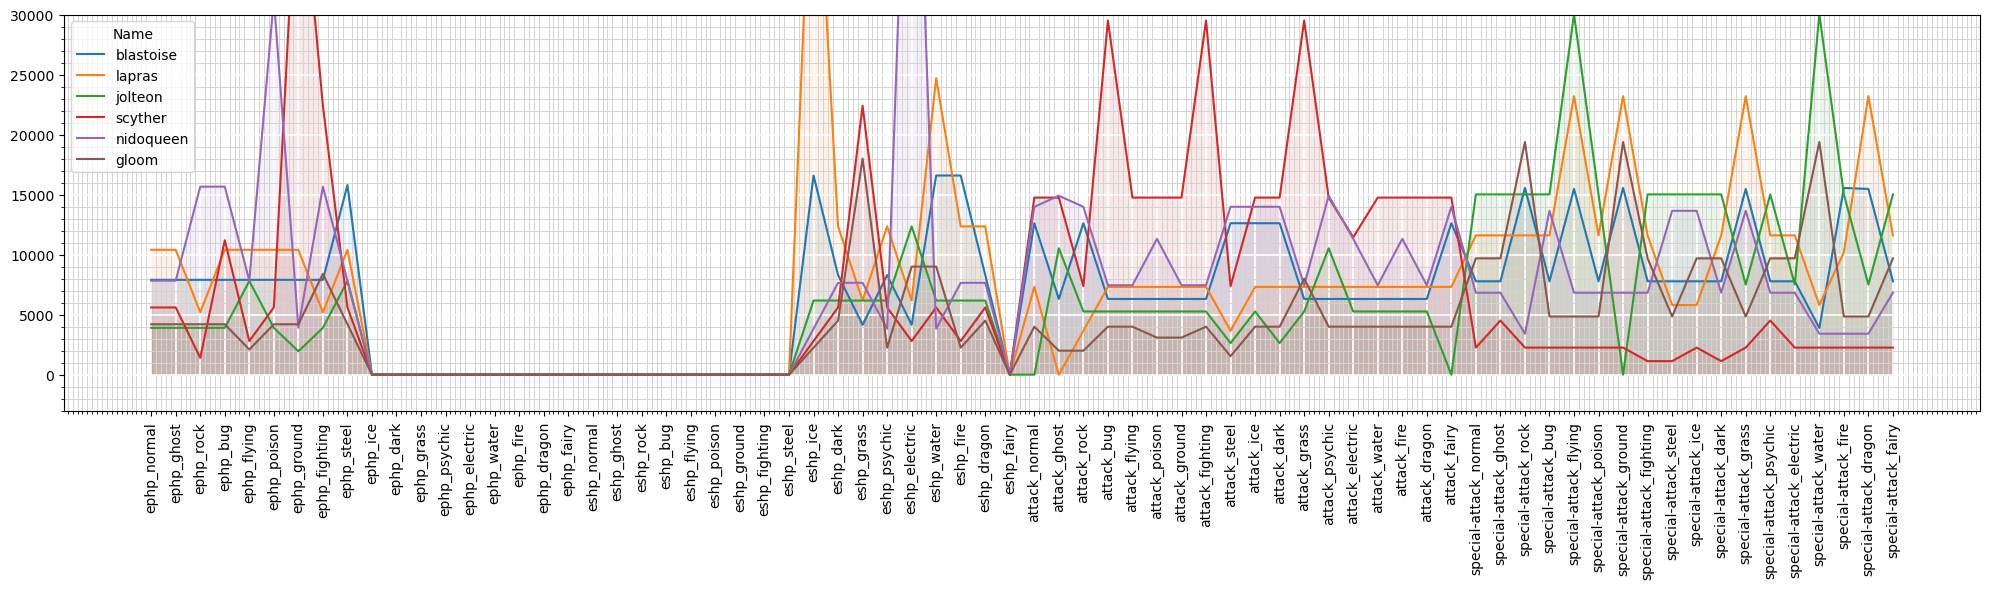

Current Stage,BLASTOISE,LAPRAS,JOLTEON,SCYTHER,NIDOQUEEN,GLOOM


Time elapsed: 1.09455120 s | Complete.


,Current Stage,Level,HP,ATK,SPATK,DEF,SPDEF,SPD,BST,Outstanding HMs,Preference,Types,Strengths,Resistances,Moveset,HMs,Priority Moves,Autohit Moves,ET
64,Blastoise,42,79,83,85,100,105,78,530,False,🤝,Water,Fire,FireSteel,"Water Pulse (61BP, S)Ice Beam (91BP, S) [TM]Iron Tail (76BP, P) [TM]Brick Break (76BP, P) [TM]",,,,0.0
4927,Lapras,42,130,85,85,80,95,60,535,False,,WaterIce,DragonElectricGrassGround,DarkDragonFlyingGhostIceNormalPsychicWater,"Water Gun (40BP, S)Ice Beam (91BP, S)Body Slam (86BP, P)Sing (0BP, S)",,,Shock Wave,139455.0
4053,Jolteon,42,65,65,110,60,95,130,525,False,,Electric,BugDarkFairyFightingFlyingGhostIceNormalPoisonPsychicSteelWater,,"Thunderbolt (91BP, S) [TM]Shock Wave (61BP, S) [TM]Shadow Ball (81BP, P) [TM]Thunder Wave (0BP, S)",,Quick Attack,Shock Wave,122122.0
4268,Scyther,42,70,110,55,80,80,105,500,False,,BugFlying,BugDarkDragonElectricFairyFightingFireFlyingGrassGroundIceNormalPoisonWater,FightingGrassGround,"Aerial Ace (61BP, P) [TM]Slash (71BP, P)Pursuit (41BP, S)Swords Dance (0BP, S)",,Quick Attack,Aerial Ace,0.0
968,Nidoqueen,42,90,92,75,87,85,76,505,False,,PoisonGround,GhostPsychicRockSteel,BugElectricPoisonRock,"Dig (41BP, P) [TM]Flamethrower (91BP, S) [TM]Shadow Ball (81BP, P) [TM]Brick Break (76BP, P) [TM]",,,Aerial AceShock Wave,0.0
2518,Gloom,42,60,65,85,70,75,40,395,True,,GrassPoison,Rock,,"Acid (41BP, P)Giga Drain (76BP, S) [TM]Cut (48BP, P) [TM]Stun Spore (0BP, S)",Cut,,,26912.5


'\nAdd Screens to EFFECT_IDS\n'

In [109]:
### RUNTIME 
pokemon = ['!bulbasaur !squirtle caterpie weedle rattata pidgey mankey spearow pikachu ',
'nidoran-m nidoran-f magikarp jigglypuff zubat geodude paras clefairy sandshrew ekans ',
'bellsprout oddish abra meowth farfetchd ',
'drowzee diglett mr-mime voltorb machop onix vulpix growlithe flareon jolteon vaporeon pinsir scyther dratini porygon ',
'gastly hitmonlee hitmonchan cubone lapras doduo snorlax vileplume ',
'venonat krabby horsea psyduck slowpoke tentacool poliwag exeggcute rhyhorn scyther pinsir chansey goldeen kangaskhan tauros ',
'lickitung articuno moltres zapdos seel kabuto aerodactyl grimer koffing ',
'jynx hitmonlee hitmonchan gastly cubone snorlax lapras aerodactyl kabuto omanyte venonat krabby horsea goldeen doduo exeggcute kangaskhan scyther rhyhorn psyduck slowpoke horsea seel tentacool staryu grimer koffing arcanine ekans jolteon poliwrath oddish flareon ',
'']

CHECKPOINT = 5

pokemon = " ".join(pokemon[:CHECKPOINT])

# TODO Currently unused
pokemon_available_moves = {
    "squirtle": ["water-pulse", ],
    "paras": ["bullet-seed", "thief"],
}
pokemon_mandatory_damaging_moves = "" # WIP
pokemon_mandatory_other_moves = ""
pokemon_banned_moves = "" # WIP

type_restrictions = [] # TODO Currently unused
level_cap = level_caps_db["frlg"][CHECKPOINT]
evolution_details = {} # TODO Currently unused
good_stats = {"HP": 90, "ATK": 100, "SPATK": 100, "DEF": 110, "SPDEF": 110, "SPD": 100} # TODO Currently unused
type_coverage_threshold = 1
outliers = {} # TODO Currently unused
hms_required = ["fly", "surf", "strength", "cut"]
# available_tms = []
# "swords-dance", 
# available_tms = ["rock-tomb", "bullet-seed", "thief", "attract", "water-pulse", "secret-power", "dig", "shock-wave", "aerial-ace", "light-screen", "reflect", "safeguard", "psychic", "calm-mind"]
# "fly", "cut", "surf", "strength"
available_tms = ["rock-tomb", "bullet-seed", "thief", "roar", "attract", "water-pulse", "secret-power", "dig", "brick-break", "cut", "shock-wave", "aerial-ace", "light-screen", "reflect", "safeguard", "psychic", "giga-drain", "calm-mind", "toxic", "fire-blast", "earthquake", "dragon-claw"]
available_tms = ["rock-tomb", "roar", "attract", "secret-power", "dig", "brick-break", "cut", "shock-wave", "aerial-ace", "light-screen", "reflect", "safeguard", "psychic", "giga-drain"]
eternal_tms = ["roar", "dig", "secret-power", "hyper-beam", "brick-break", "attract", "ice-beam", "thunderbolt", "flamethrower", "iron-tail", "shadow-ball"]
# eternal_tms = []
used_tms = []
all_tms = list(set(available_tms) | set(eternal_tms) - set(used_tms)) # TODO we may want to move the 'eternal_tms' here into the parse_moves function
trim_results = True

f_db, r_db = run(pokemon, pokemon_available_moves, pokemon_mandatory_damaging_moves, pokemon_mandatory_other_moves, pokemon_banned_moves, ignore, type_restrictions, level_cap, evolution_details, good_stats, type_coverage_threshold, outliers, hms_required, all_tms, eternal_tms, trim_results)

"""
Add Screens to EFFECT_IDS
"""

In [104]:
# display(f_db)


In [105]:
enemy_pokemon = """
voltorb.21 - shock-wave tackle screech sonicboom 
pikachu.18 - shock-wave thunder-wave quick-attack double-team 
raichu.24 - shock-wave thunder-wave quick-attack double-team 
"""

my_pokemon = "\n".join(r_db.apply(lambda x: f"{x['Current Stage']} - {' '.join(x['Moveset']['identifier'].to_list())}", axis=1).to_list())

print(f"LV.{level_cap}")

parse_best_matchups(r_db, f_db, enemy_pokemon)

LV.42


,pokemon,level,HP,ATK,SPATK,DEF,SPDEF,SPD,moves
0,voltorb,21,40,30,55,50,55,100,"[tackle, screech, shock-wave]"
1,pikachu,18,35,55,50,40,50,90,"[thunder-wave, quick-attack, double-team, shock-wave]"
2,raichu,24,60,90,90,55,80,110,"[thunder-wave, quick-attack, double-team, shock-wave]"


,Current Stage,Level,HP,ATK,SPATK,DEF,SPDEF,SPD,BST,Preference,Types,Moveset,voltorb,pikachu,raichu
64,blastoise,42,79,83,85,100,105,78,530,🤝,Water,"Water Pulse (61BP, S)Ice Beam (91BP, S) [TM]Iron Tail (76BP, P) [TM]Brick Break (76BP, P) [TM]",IN: shock-wave (69%)OUT: water-pulse (33%)ODDS: 0.48,IN: shock-wave (59%)OUT: water-pulse (40%)ODDS: 0.68,IN: shock-wave (88%)OUT: water-pulse (23%)ODDS: 0.27
4927,lapras,42,130,85,85,80,95,60,535,,WaterIce,"Water Gun (40BP, S)Ice Beam (91BP, S)Body Slam (86BP, P)Sing (0BP, S)",IN: shock-wave (55%)OUT: ice-beam (47%)ODDS: 0.86,IN: shock-wave (48%)OUT: ice-beam (57%)ODDS: 1.19 ⭐,IN: shock-wave (71%)OUT: ice-beam (32%)ODDS: 0.46
4053,jolteon,42,65,65,110,60,95,130,525,,Electric,"Thunderbolt (91BP, S) [TM]Shock Wave (61BP, S) [TM]Shadow Ball (81BP, P) [TM]Thunder Wave (0BP, S)",IN: tackle (26%)OUT: thunderbolt (29%)ODDS: 1.12 ⭐💨,IN: quick-attack (25%)OUT: thunderbolt (36%)ODDS: 1.44 ⭐💨,IN: quick-attack (37%)OUT: thunderbolt (20%)ODDS: 0.55
4268,scyther,42,70,110,55,80,80,105,500,,BugFlying,"Aerial Ace (61BP, P) [TM]Slash (71BP, P)Pursuit (41BP, S)Swords Dance (0BP, S)",IN: shock-wave (93%)OUT: slash (32%)ODDS: 0.35,IN: shock-wave (80%)OUT: slash (39%)ODDS: 0.49,IN: shock-wave (119%)OUT: slash (23%)ODDS: 0.2
968,nidoqueen,42,90,92,75,87,85,76,505,,PoisonGround,"Dig (41BP, P) [TM]Flamethrower (91BP, S) [TM]Shadow Ball (81BP, P) [TM]Brick Break (76BP, P) [TM]",IN: tackle (16%)OUT: shadow-ball (31%)ODDS: 1.94 ⭐,IN: quick-attack (15%)OUT: shadow-ball (38%)ODDS: 2.54 ⭐,IN: quick-attack (22%)OUT: shadow-ball (23%)ODDS: 1.05 ⭐
2518,gloom,42,60,65,85,70,75,40,395,,GrassPoison,"Acid (41BP, P)Giga Drain (76BP, S) [TM]Cut (48BP, P) [TM]Stun Spore (0BP, S)",IN: shock-wave (27%)OUT: giga-drain (40%)ODDS: 1.49 ⭐,IN: quick-attack (23%)OUT: giga-drain (49%)ODDS: 2.14 ⭐,IN: quick-attack (34%)OUT: giga-drain (27%)ODDS: 0.8


In [106]:
# # r_db.loc[3,:].to_frame().transpose()
# # r_db
# for j in range(0, 10):
#     i = j * 10
#     print(i, (87/1.9-2)*50/(2*i/5+2))

sum([float(i) for i in "4035.15	0.0	0.0	0.0	0.0	0.0	8070.3	4035.15	4035.15	2017.575	0.0	4035.15	4035.15	4035.15	0.0	0.0	4035.15	0.0	0.0	2562.0	10248.0	10248.0	20496.0	2562.0	0.0	0.0	0.0	0.0	2562.0	0.0	0.0	0.0	5124.0	5124.0	0.0	0.0	0.0	0.0	3100.0	3100.0	3100.0	3100.0	3100.0	3100.0	3100.0	3100.0	3100.0	3100.0	3100.0	3100.0	1550.0	0.0	3100.0	3100.0	1550.0	3100.0	7320.0	3660.0	14640.0	7320.0	3660.0	7320.0	7320.0	3660.0	14640.0	3660.0	7320.0	3660.0	14640.0	7320.0	3660.0	7320.0	3660.0	7320.0	".split("\t") if i])

274959.925

In [107]:
print(len({1:1, 2:2, 3:3}))

raise Exception()

3


Exception: 

In [ ]:
TYPE_CHART

In [ ]:
represented_pokemon = "venusaur dragonite vaporeon nidoqueen gyarados kabutops " \
"blastoise nidoking arcanine jolteon aerodactyl poliwrath " \
"charizard snorlax alakazam raichu dewgong rhydon " \
"butterfree beedrill lapras flareon omastar marowak " \
"sceptile tentacruel flygon gardevoir heracross relicanth " \
"blaziken slaking golduck cacturne altaria manectric " \
"swampert donphan ludicolo dodrio breloom magneton " \
"torterra lucario luxray honchkrow weavile rapidash " \
"infernape garchomp abomasnow staraptor floatzel pachirisu " \
"empoleon togekiss roserade houndoom gastrodon froslass " \
"grumpig aggron machamp sharpedo weezing xatu " \
"dusknoir gallade mamoswine magnezone hippowdon pelipper " \
"meganium magmortar cloyster noctowl corsola quagsire " \
"typhlosion rhyperior starmie ampharos skarmory magcargo " \
"feraligatr steelix mantine pidgeot primeape lanturn "

completed_runs = "bug psychic ghost"

list_of_first_types = [get_first_type(get_pokemon_id_from_name(t)) for t in represented_pokemon.split(" ") if t]
list_of_second_types = [get_second_type(get_pokemon_id_from_name(t)) for t in represented_pokemon.split(" ") if t]
list_of_types = [t for t in list_of_first_types + list_of_second_types if len(t) > 0]
list_of_types = [(t, list_of_types.count(t)) for t in [t.lower() for t in TYPE_CHART.index]]

list_of_types = sorted(list_of_types, key=lambda x: (x[0] in completed_runs, x[1]))

list_of_types = [(f"{'**' if t[0] in completed_runs else ''}{t[0]}", t[1]) for t in list_of_types]

list_of_types

In [ ]:
TYPE_CHART

In [ ]:
raise Exception("Script ends here.")

In [ ]:

# outliers = ["torterra", "cranidos", "roserade", "mismagius", "medicham", "lucario", "gyarados", "quagsire", "bastiodon", "abomasnow", "froslass", "electivire", "vespiquen", "drapion", "gliscor", "infernape", "gallade", "bronzong^ground", "garchomp", "spiritomb", "milotic", "togekiss"]
# outliers = ["nosepass", "makuhita", "magneton", "manectric", "camerupt", "torkoal", "slaking", "skarmory", "altaria", "lunatone", "claydol^levitate", "xatu", "kingdra", "whiscash", "mightyena", "dusclops", "walrein", "flygon", "salamence", "milotic"]
# outliers = ["pidgeot", "scyther", "miltank", "gengar^ground", "poliwrath", "steelix", "piloswine", "kingdra", "xatu", "jynx", "exeggutor", "slowbro", "bronzong", "slowbro", "ariados", "forretress", "machamp", "houndoom", "gyarados", "dragonite", "aerodactyl", "charizard"]
# outliers = ["excadrill", "haxorus", "hydreigon"]
# moves_required = ["fly", "surf", "rock-smash"] 
# moves_required = ["fly"]

In [ ]:
pokemon_frlg = "!caterpie|psychic|bug !weedle|fighting|poison rattata pidgey mankey spearow raichu|fighting nidoking|fighting,bug,ice|poison nidoqueen|fighting|poison magikarp|dark zubat geodude paras||bug,grass kabuto|ground|water omanyte sandshrew jynx " \
"bellsprout alakazam|ghost meowth diglett machop onix ninetales vaporeon|ice,dark clefairy pinsir|fighting|bug dratini|ice porygon hitmonlee hitmonchan gastly cubone snorlax lapras aerodactyl venonat krabby horsea goldeen doduo " \
"exeggcute||psychic kangaskhan scyther||bug rhyhorn psyduck slowpoke horsea seel tentacool staryu grimer koffing arcanine|dark ekans jolteon|ghost,dark poliwrath oddish flareon|dark"

pokemon_rs = "!torchic|flying zigzagoon silcoon cascoon poochyena wingull seedot lotad ralts|electric taillow slakoth|ice shroomish whismur nincada !tentacool|ice makuhita aron sableye mawile geodude " \
"electrike|dark minun plusle gulpin " \
"oddish roselia volbeat illumise oddish marill goldeen " \
"numel machop koffing grimer torkoal slugma spinda skarmory sandshrew " \
"swablu zangoose seviper lunatone solrock spoink " \
"trapinch|dark,flying cacnea baltoy lileep anorith " \
"magnemite voltorb carvanha|ice tropius feebas absol barboach " \
"shuppet duskull wailmer girafarig doduo natu wobbuffet psyduck|ice pinsir phanpy heracross||bug meditite vulpix chimecho " \
"spheal snorunt " \
"clamperl relicanth chinchou"
"" 

pokemon_emerald = "!spoink poochyena silcoon cascoon wingull ralts lotad seedot marill taillow shroomish slakoth " \
"nincada whismur skitty " \
"makuhita zubat abra geodude aron|ground,fighting sableye electrike minun gulpin oddish plusle " \
"illumise volbeat nosepass numel koffing|fire,electric torkoal machop|ground slugma grimer|ghost skarmory seviper solrock spoink " \
"sandshrew trapinch baltoy cacnea lileep||grass anorith " \
"jigglypuff magnemite voltorb carvanha|ice tropius absol goldeen castform " \
"shuppet wailmer vulpix chimecho duskull girafarig doduo natu|grass wobbuffet rhyhorn pinsir phanpy|rock heracross " \
"spheal snorunt corsola horsea " \
"lanturn chinchou relicanth " \
"bagon " \
# "mareep sunkern spinarak aipom hoothoot gligar snubbull stantler teddiursa ledyba pineco houndour miltank shuckle " \
""

pokemon_dp = "!chimchar|rock starly|fighting bidoof||water shinx|dark,steel kricketot roserade||poison zubat machop onix " \
"pachirisu buizel|dark shellos silcoon cascoon mothim wormadam-plant wormadam-sandy wormadam-trash cherubi aipom combee " \
"buneary honchkrow|ghost misdreavus ponyta chingling meditite hoothoot cleffa " \
"gastly geodude stunky bronzor cleffa chansey bonsly " \
"sudowoodo hippopotas|dark girafarig marill wooper roselia skorupi croagunk carnivine barboach " \
"finneon lucario|dragon steelix|dark " \
"snover weavile|steel,ghost " \
"wingull glameow chatot remoraid " \
"gible|dark " \
""

pokemon_plt = "!duskull|fighting starly bidoof shinx kricketot zubat abra psyduck geodude onix " \
"silcoon cascoon budew pachirisu buizel shellos gastly buneary hoothoot|psychic chatot drifloon " \
"togepi|electric,rock rotom machop gligar||flying bronzor machop clefairy nosepass meditite chingling gallade|flying umbreon espeon leafeon " \
"chansey duskull goldeen scyther abra lickitung marill porygon|psychic,bug flareon vaporeon jolteon " \
"rhyhorn houndour hippopotas|dark girafarig chatot remoraid " \
"quagsire croagunk swablu magnemite magmar finneon wingull sudowoodo " \
"sneasel snover swinub froslass absol electabuzz glaceon " \
# "mantyke" \
""

pokemon_hgss = "!porygon|ice,electric,bug||agility pidgey|bug rattata sentret hoothoot|psychic,ghost caterpie weedle ledyba spinarak togepi mareep|bug wooper slugma|||yawn,recover gastly bellsprout " \
"ekans hoppip sandshrew zubat geodude|||rockpolish,explosion onix|dark goldeen spearow slowpoke slowking " \
"oddish paras pineco politoed abra drowzee krabby exeggcute " \
"yanma sunkern paras venonat scyther pinsir vulpix|dark||burn,confuse growlithe stantler sudowoodo magmar|fighting,electric||confuse flareon vaporeon jolteon espeon umbreon " \
"meowth magnemite farfetchd tauros snubbull miltank corsola staryu mantine|ice chinchou|bug||confuse shellder shuckle " \
" " \
"mankey|dark,ground heracross aipom girafarig " \
"lickitung tangela remoraid jynx swinub delibird " \
# "dratini gligar teddiursa skarmory|dark||spikes phanpy wobbuffet dunsparce sandslash ponyta rhyhorn|fighting"

pokemon_bw = pokemon = "!snivy|||absorb,setup !tepig|||boost !oshawott|||prio lillipup patrat purrloin pansage " \
# "munna pidove blitzle audino roggenrola woobat drilbur " \
# "tympole|||boost,heal timburr sawk throh sewaddle cottonee petilil venipede pansage pansear panpour " \
# "sandile darumaka|ground|normal,rock scraggy maractus dwebble yamask tirtouga archen " \
# "ducklett basculin-red-striped vanillite minccino gothita solosis||rock trubbish " \
# "deerling||dark karrablast foongus emolga joltik klink ferroseed tynamo cubchoo litwick elgyem " \
# "larvesta frillish|||boost,sustain alomomola axew cryogonal shelmet stunfisk " \
# "mienfoo druddigon golett " \
# "rufflet vullaby bouffalant heatmor"